
# Kenya Electoral Participation Analytics
## Notebook 05 — Electoral Participation Visualisation and Reporting

### Purpose
Develop clear, reproducible visualisations and evidence-based findings
from the validated analytical dataset prepared in Notebooks 01–04.

### Election events
- 2013 General Election
- August 2017 General Election
- October 2017 Fresh Presidential Election
- 2022 General Election

### Analytical approach
- Use all 47 counties where the required data is available.
- Use a consistent 45-county sample for comparisons requiring
  validated August 2017 participation.
- Distinguish valid-vote participation from electoral turnout.
- Keep the October 2017 fresh election separate from general-election trends.
- Preserve source limitations and validation flags.
- Do not modify original or processed source datasets.

### Expected outputs
1. Publication-quality charts.
2. County-level participation comparisons.
3. Registration and valid-vote growth visualisations.
4. Documented findings and methodological limitations.
5. Visual assets for the final report and portfolio article.


### Initialise the visualisation environment
This first Python cell will locate the processed analytical dataset, verify the documentation from Notebook 04 and initialise the libraries needed for chart development.

It will not create or overwrite any files.

In [3]:

# ================================================================
# NOTEBOOK 05 — CELL 1
# INITIALISE VISUALISATION AND REPORTING ENVIRONMENT
# ================================================================
# Purpose:
# 1. Establish project directories.
# 2. Confirm the analytical dataset exists.
# 3. Verify Notebook 04 documentation.
# 4. Initialise visualisation libraries.
# 5. Confirm the environment is ready.
#
# No files are created or modified.
# ================================================================

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ------------------------------------------------
# STEP 1: ESTABLISH PROJECT ROOT
# ------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "kenya_county_election_analytics.csv"
)

DOCS_DIR = PROJECT_ROOT / "documentation"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

# ------------------------------------------------
# STEP 2: VERIFY REQUIRED INPUTS
# ------------------------------------------------

required_files = {
    "Analytical dataset": DATA_PATH,
    "Notebook 04 validation summary":
        DOCS_DIR / "notebook04_validation_summary.csv",
    "Notebook 04 key findings":
        DOCS_DIR / "notebook04_key_findings.csv",
    "Notebook 04 analysis summary":
        DOCS_DIR / "notebook04_analysis_summary.md"
}

input_checks = []

for name, path in required_files.items():
    exists = path.is_file()

    input_checks.append({
        "input": name,
        "status": "FOUND" if exists else "MISSING",
        "path": str(path)
    })

input_checks_df = pd.DataFrame(input_checks)

print("NOTEBOOK 05 — INPUT VERIFICATION")
print("=" * 65)

display(input_checks_df)

assert input_checks_df["status"].eq("FOUND").all(), (
    "One or more required Notebook 05 inputs are missing."
)

# ------------------------------------------------
# STEP 3: VERIFY NOTEBOOK 04 VALIDATION
# ------------------------------------------------

previous_validation = pd.read_csv(
    DOCS_DIR / "notebook04_validation_summary.csv"
)

assert len(previous_validation) == 10, (
    "Unexpected number of Notebook 04 validation checks."
)

assert previous_validation["status"].eq("PASS").all(), (
    "Notebook 04 validation contains failed checks."
)

# ------------------------------------------------
# STEP 4: CONFIGURE VISUALISATION DEFAULTS
# ------------------------------------------------

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# ------------------------------------------------
# STEP 5: DISPLAY ENVIRONMENT SUMMARY
# ------------------------------------------------

print("\nVISUALISATION ENVIRONMENT")
print("=" * 65)

print("Project root:", PROJECT_ROOT)
print("Analytical dataset:", DATA_PATH)
print("Documentation directory:", DOCS_DIR)
print("Planned figures directory:", FIGURES_DIR)

print("\nLibraries:")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

print("\nPrevious notebook validation:")
print("Checks:", len(previous_validation))
print(
    "All passed:",
    previous_validation["status"].eq("PASS").all()
)

print("\nNOTEBOOK 05 ENVIRONMENT INITIALISATION: PASSED")


NOTEBOOK 05 — INPUT VERIFICATION


,input,status,path
0,Analytical dataset,FOUND,C:\Users\user\Downloads\Kenya Electoral Partic...
1,Notebook 04 validation summary,FOUND,C:\Users\user\Downloads\Kenya Electoral Partic...
2,Notebook 04 key findings,FOUND,C:\Users\user\Downloads\Kenya Electoral Partic...
3,Notebook 04 analysis summary,FOUND,C:\Users\user\Downloads\Kenya Electoral Partic...



VISUALISATION ENVIRONMENT
Project root: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project
Analytical dataset: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\data\processed\kenya_county_election_analytics.csv
Documentation directory: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\documentation
Planned figures directory: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\reports\figures

Libraries:
Pandas: 2.1.4
NumPy: 1.26.4
Matplotlib: 3.8.0

Previous notebook validation:
Checks: 10
All passed: True

NOTEBOOK 05 ENVIRONMENT INITIALISATION: PASSED


### Load and validate the analytical dataset
This cell will load the final dataset produced in Notebook 03 and verify that its structure and important data-quality flags remain intact.

In [6]:

# ================================================================
# NOTEBOOK 05 — CELL 2
# LOAD AND VALIDATE THE ANALYTICAL DATASET
# ================================================================

# ------------------------------------------------
# STEP 1: LOAD DATA
# ------------------------------------------------

elections_df = pd.read_csv(
    DATA_PATH,
    dtype={"county_key": "string"}
)

print("ANALYTICAL DATASET LOADED")
print("=" * 65)

print("Rows:", len(elections_df))
print("Columns:", len(elections_df.columns))

# ------------------------------------------------
# STEP 2: VERIFY EXPECTED STRUCTURE
# ------------------------------------------------

expected_events = {
    "2013_GENERAL",
    "2017_AUG_GENERAL",
    "2017_OCT_FRESH",
    "2022_GENERAL"
}

assert elections_df.shape == (188, 20), (
    f"Unexpected dataset shape: {elections_df.shape}"
)

assert set(elections_df["election_id"]) == expected_events, (
    "Unexpected election identifiers."
)

assert elections_df["county_key"].nunique() == 47, (
    "Expected 47 unique counties."
)

assert not elections_df.duplicated(
    subset=["election_id", "county_key"]
).any(), (
    "Duplicate election-county records detected."
)

# ------------------------------------------------
# STEP 3: CHECK ELECTION COVERAGE
# ------------------------------------------------

event_summary = (
    elections_df
    .groupby("election_id", as_index=False)
    .agg(
        counties=("county_key", "nunique"),
        registered_available=(
            "analytical_registered_voters",
            "count"
        ),
        valid_votes_available=(
            "analytical_valid_votes",
            "count"
        ),
        ballots_cast_available=(
            "analytical_ballots_cast",
            "count"
        )
    )
)

assert event_summary["counties"].eq(47).all(), (
    "One or more elections have incomplete county coverage."
)

print("\nELECTION COVERAGE")
display(event_summary)

# ------------------------------------------------
# STEP 4: VERIFY KNOWN SOURCE LIMITATIONS
# ------------------------------------------------

august_2017 = elections_df.loc[
    elections_df["election_id"] == "2017_AUG_GENERAL"
]

october_2017 = elections_df.loc[
    elections_df["election_id"] == "2017_OCT_FRESH"
]

election_2022 = elections_df.loc[
    elections_df["election_id"] == "2022_GENERAL"
]

# Kisumu and Turkana have unresolved August 2017
# source discrepancies affecting analytical valid votes.
august_missing = set(
    august_2017.loc[
        august_2017["analytical_valid_votes"].isna(),
        "county_key"
    ].str.upper()
)

assert august_missing == {"KISUMU", "TURKANA"}, (
    f"Unexpected August 2017 missing counties: {august_missing}"
)

# The October 2017 event must remain separate.
assert len(october_2017) == 47

# All 2022 ballots-cast values remain unavailable.
assert election_2022[
    "analytical_ballots_cast"
].isna().all(), (
    "Unexpected 2022 ballots-cast values."
)

# The 2022 source verification status must be preserved.
assert election_2022[
    "validation_status"
].eq("COUNTY_SOURCE_UNVERIFIED").all(), (
    "Unexpected 2022 validation status."
)

# ------------------------------------------------
# STEP 5: DISPLAY VALIDATION STATUS
# ------------------------------------------------

validation_summary = (
    elections_df
    .groupby(
        ["election_id", "validation_status"],
        dropna=False
    )
    .size()
    .reset_index(name="counties")
)

print("\nSOURCE VALIDATION STATUS")
display(validation_summary)

print("\nNOTEBOOK 05 — DATASET VALIDATION: PASSED")


ANALYTICAL DATASET LOADED
Rows: 188
Columns: 20

ELECTION COVERAGE


,election_id,counties,registered_available,valid_votes_available,ballots_cast_available
0,2013_GENERAL,47,47,47,47
1,2017_AUG_GENERAL,47,47,45,45
2,2017_OCT_FRESH,47,47,47,47
3,2022_GENERAL,47,47,47,0



SOURCE VALIDATION STATUS


,election_id,validation_status,counties
0,2013_GENERAL,PARTIALLY_RECONCILED,47
1,2017_AUG_GENERAL,EXCEPTIONS_DOCUMENTED,47
2,2017_OCT_FRESH,COUNTY_RECONCILED,47
3,2022_GENERAL,COUNTY_SOURCE_UNVERIFIED,47



NOTEBOOK 05 — DATASET VALIDATION: PASSED


**Interpretation of Cell 2**

Three methodological decisions will guide our charts:
1. Use valid-vote participation for comparisons involving 2022. We cannot calculate actual ballots-cast turnout for 2022 because those county figures are unavailable.
2. Use a consistent 45-county sample for longitudinal comparisons involving August 2017. Kisumu and Turkana remain excluded from those comparisons.
3. Present October 2017 separately. It was a fresh presidential election rather than an ordinary general election.
These distinctions will prevent us from presenting incomplete or provisional measures as directly comparable national turnout estimates.

### Prepare the national participation trend
Our first visualisation will compare valid-vote participation across the three general elections.

For this chart, we'll use the same 45 counties in every election. This avoids comparing a 47-county figure in one year against a 45-county figure in another.

The calculation is:
$$
\text{Valid-vote participation (\%)} =
\frac{\text{Total valid votes in comparable counties}}
{\text{Total registered voters in comparable counties}}
\times 100
$$

In [13]:

# ================================================================
# NOTEBOOK 05 — CELL 3
# PREPARE COMPARABLE GENERAL-ELECTION PARTICIPATION DATA
# ================================================================
# Purpose:
# 1. Select the three general elections.
# 2. Establish a consistent 45-county analytical sample.
# 3. Calculate registration-weighted valid-vote participation.
# 4. Verify the underlying data before charting.
#
# No files are created or modified.
# ================================================================

# ------------------------------------------------
# STEP 1: DEFINE GENERAL ELECTIONS
# ------------------------------------------------

general_election_ids = [
    "2013_GENERAL",
    "2017_AUG_GENERAL",
    "2022_GENERAL"
]

election_labels = {
    "2013_GENERAL": "2013 General",
    "2017_AUG_GENERAL": "August 2017 General",
    "2022_GENERAL": "2022 General"
}

# ------------------------------------------------
# STEP 2: IDENTIFY COMPARABLE COUNTIES
# ------------------------------------------------

# August 2017 determines the consistent sample
# because Kisumu and Turkana have unresolved
# valid-vote source discrepancies.

august_usable_counties = set(
    elections_df.loc[
        (elections_df["election_id"] == "2017_AUG_GENERAL")
        & elections_df["analytical_valid_votes"].notna()
        & elections_df["analytical_registered_voters"].notna(),
        "county_key"
    ]
)

assert len(august_usable_counties) == 45, (
    "Expected 45 comparable counties."
)

# ------------------------------------------------
# STEP 3: FILTER THE ANALYTICAL DATASET
# ------------------------------------------------

general_trend_df = elections_df.loc[
    elections_df["election_id"].isin(general_election_ids)
    & elections_df["county_key"].isin(august_usable_counties)
].copy()

assert len(general_trend_df) == 135, (
    "Expected 45 counties across three elections."
)

assert not general_trend_df[
    [
        "analytical_registered_voters",
        "analytical_valid_votes"
    ]
].isna().any().any(), (
    "Missing values found in comparable election data."
)

# ------------------------------------------------
# STEP 4: CALCULATE WEIGHTED PARTICIPATION
# ------------------------------------------------

national_trend = (
    general_trend_df
    .groupby("election_id", as_index=False)
    .agg(
        counties=("county_key", "nunique"),
        registered_voters=(
            "analytical_registered_voters",
            "sum"
        ),
        valid_votes=(
            "analytical_valid_votes",
            "sum"
        )
    )
)

national_trend["valid_vote_participation_pct"] = (
    national_trend["valid_votes"]
    / national_trend["registered_voters"]
    * 100
)

national_trend["election"] = (
    national_trend["election_id"].map(election_labels)
)

# Preserve chronological order.
national_trend["election_id"] = pd.Categorical(
    national_trend["election_id"],
    categories=general_election_ids,
    ordered=True
)

national_trend = (
    national_trend
    .sort_values("election_id")
    .reset_index(drop=True)
)

# ------------------------------------------------
# STEP 5: CALCULATE CHANGE OVER TIME
# ------------------------------------------------

national_trend["change_from_previous_pp"] = (
    national_trend["valid_vote_participation_pct"].diff()
)

overall_change_pp = (
    national_trend.loc[
        2, "valid_vote_participation_pct"
    ]
    - national_trend.loc[
        0, "valid_vote_participation_pct"
    ]
)

# ------------------------------------------------
# STEP 6: VALIDATION
# ------------------------------------------------

assert national_trend["counties"].eq(45).all(), (
    "County sample is not consistent."
)

assert national_trend[
    "valid_vote_participation_pct"
].between(0, 100).all(), (
    "Participation rate outside the expected range."
)

assert (
    national_trend["valid_vote_participation_pct"]
    .diff()
    .dropna()
    .lt(0)
    .all()
), (
    "Unexpected participation trend: review the data."
)

# ------------------------------------------------
# STEP 7: DISPLAY RESULTS
# ------------------------------------------------

print("COMPARABLE GENERAL-ELECTION PARTICIPATION")
print("=" * 65)

display(
    national_trend[
        [
            "election",
            "counties",
            "registered_voters",
            "valid_votes",
            "valid_vote_participation_pct",
            "change_from_previous_pp"
        ]
    ].round(2)
)

print(
    "\nOverall change, 2013 to 2022:",
    f"{overall_change_pp:.2f} percentage points"
)

print("\nNOTEBOOK 05 — CELL 3 VALIDATION: PASSED")


COMPARABLE GENERAL-ELECTION PARTICIPATION


,election,counties,registered_voters,valid_votes,valid_vote_participation_pct,change_from_previous_pp
0,2013 General,45,13865112,11770740.0,84.89,NaN
1,August 2017 General,45,18876036,14571915.0,77.20,-7.70
2,2022 General,45,21263965,13632612.0,64.11,-13.09



Overall change, 2013 to 2022: -20.78 percentage points

NOTEBOOK 05 — CELL 3 VALIDATION: PASSED


One particularly interesting finding is that valid votes increased between 2013 and August 2017 but subsequently fell between August 2017 and 2022, even as registered voters continued to increase.

This gives us a strong analytical narrative: growth in the registered electorate did not translate into proportionate growth in valid votes cast.

These findings describe the 45-county comparable sample, not all 47 counties.

### Create our first publication-quality chart
We will produce a line chart showing the trend across the three general elections. It will include precise percentage labels, a clear subtitle, a source note and the sample limitations.

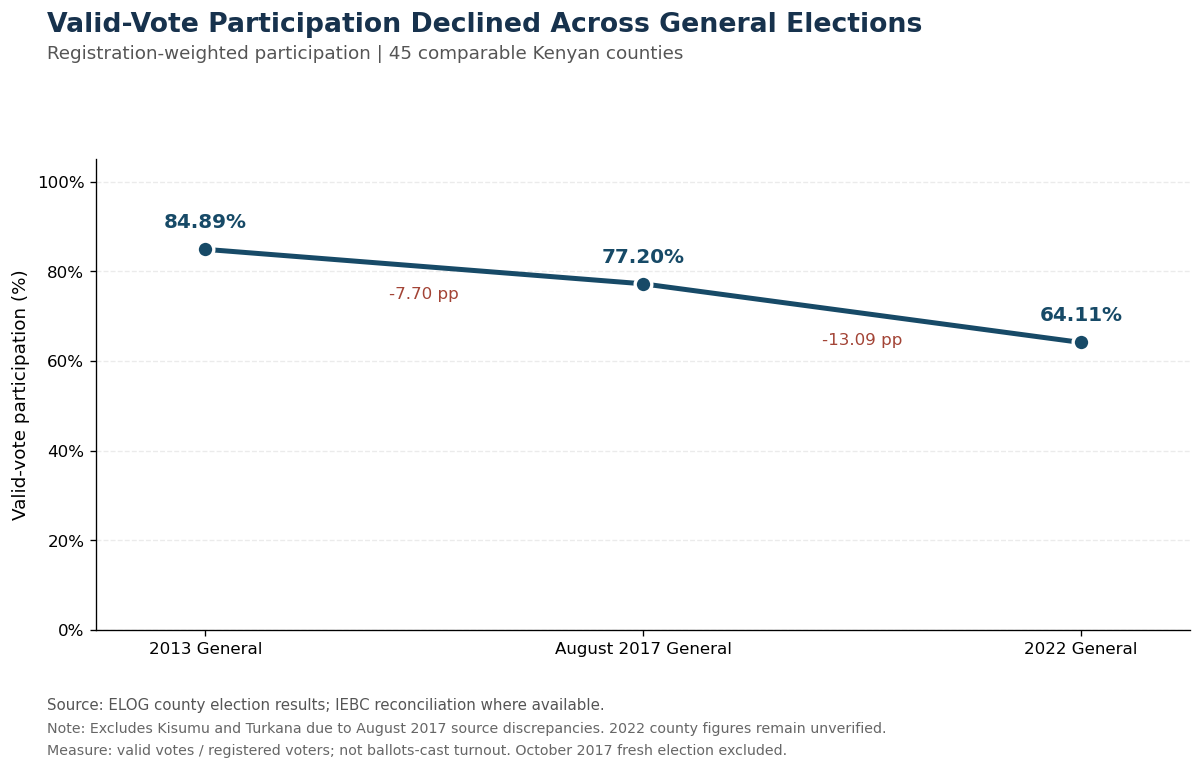


NOTEBOOK 05 — FIRST CHART SAVED
File: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\reports\figures\01_general_election_valid_vote_participation.png
File size: 262.7 KB
Export resolution: 300 DPI
Chart verification: PASSED
NOTEBOOK 05 — CELL 4 VISUALISATION COMPLETE
Chart displayed successfully.
No files saved at this stage.


In [20]:

# ================================================================
# NOTEBOOK 05 — CELL 4
# VISUALISE GENERAL-ELECTION VALID-VOTE PARTICIPATION
# ================================================================
# Purpose:
# 1. Create a publication-quality participation trend chart.
# 2. Show the 2013, August 2017 and 2022 general elections.
# 3. Label exact participation rates and percentage-point changes.
# 4. Document the 45-county sample and source limitations.
#
# The chart is displayed only; no files are saved yet.
# ================================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------
# STEP 1: PREPARE CHART DATA
# ------------------------------------------------

chart_df = national_trend.copy()

x = np.arange(len(chart_df))
y = chart_df["valid_vote_participation_pct"].to_numpy()

labels = [
    "2013 General",
    "August 2017 General",
    "2022 General"
]

# ------------------------------------------------
# STEP 2: CREATE FIGURE
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6.5))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Main trend line
ax.plot(
    x,
    y,
    color="#174A67",
    linewidth=3,
    marker="o",
    markersize=10,
    markerfacecolor="#174A67",
    markeredgecolor="white",
    markeredgewidth=2,
    zorder=3
)

# ------------------------------------------------
# STEP 3: LABEL PARTICIPATION VALUES
# ------------------------------------------------

for xi, yi in zip(x, y):
    ax.annotate(
        f"{yi:.2f}%",
        xy=(xi, yi),
        xytext=(0, 13),
        textcoords="offset points",
        ha="center",
        fontsize=12,
        fontweight="bold",
        color="#174A67"
    )

# ------------------------------------------------
# STEP 4: ANNOTATE CHANGES
# ------------------------------------------------

for i in range(1, len(y)):
    change = y[i] - y[i - 1]

    midpoint_x = (x[i - 1] + x[i]) / 2
    midpoint_y = (y[i - 1] + y[i]) / 2

    ax.annotate(
        f"{change:+.2f} pp",
        xy=(midpoint_x, midpoint_y),
        xytext=(0, -19),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="medium",
        color="#A34436"
    )

# ------------------------------------------------
# STEP 5: FORMAT AXES
# ------------------------------------------------

ax.set_xticks(x)
ax.set_xticklabels(labels)

ax.set_ylim(0, 105)
ax.set_xlim(-0.25, 2.25)

ax.set_ylabel(
    "Valid-vote participation (%)",
    fontsize=11
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, pos: f"{value:.0f}%")
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ------------------------------------------------
# STEP 6: ADD TITLES AND SOURCE NOTES
# ------------------------------------------------

fig.suptitle(
    "Valid-Vote Participation Declined Across General Elections",
    x=0.10,
    y=0.97,
    ha="left",
    fontsize=16,
    fontweight="bold",
    color="#17324D"
)

fig.text(
    0.10,
    0.91,
    "Registration-weighted participation | 45 comparable Kenyan counties",
    ha="left",
    fontsize=11,
    color="#555555"
)

fig.text(
    0.10,
    0.075,
    "Source: ELOG county election results; IEBC reconciliation "
    "where available.",
    fontsize=9,
    color="#555555"
)

fig.text(
    0.10,
    0.045,
    "Note: Excludes Kisumu and Turkana due to August 2017 "
    "source discrepancies. 2022 county figures remain unverified.",
    fontsize=8.5,
    color="#666666"
)

fig.text(
    0.10,
    0.018,
    "Measure: valid votes / registered voters; not ballots-cast turnout. "
    "October 2017 fresh election excluded.",
    fontsize=8.5,
    color="#666666"
)

# Reserve space for title and notes.
plt.tight_layout(rect=[0.06, 0.12, 0.98, 0.86])




# ------------------------------------------------
# STEP 7: SAVE AND DISPLAY APPROVED CHART
# ------------------------------------------------

from pathlib import Path

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

chart_path = (
    FIGURES_DIR
    / "01_general_election_valid_vote_participation.png"
)

# Protect existing chart files from accidental overwriting.
assert not chart_path.exists(), (
    f"Chart already exists: {chart_path}"
)

fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

assert chart_path.is_file(), (
    "Chart export failed."
)

plt.show()

print("\nNOTEBOOK 05 — FIRST CHART SAVED")
print("=" * 65)
print("File:", chart_path)
print("File size:", f"{chart_path.stat().st_size / 1024:.1f} KB")
print("Export resolution: 300 DPI")
print("Chart verification: PASSED")


print("NOTEBOOK 05 — CELL 4 VISUALISATION COMPLETE")

### Prepare county-level participation comparisons
Our next objective is to identify which counties experienced the largest and smallest declines in valid-vote participation between 2013 and 2022.

We will continue using the consistent 45-county sample. This cell prepares and validates the county rankings; the following cell will visualise them.

In [23]:

# ================================================================
# NOTEBOOK 05 — CELL 5
# COUNTY-LEVEL PARTICIPATION CHANGE: 2013 VS 2022
# ================================================================
# Purpose:
# 1. Compare valid-vote participation across 45 counties.
# 2. Calculate percentage-point changes from 2013 to 2022.
# 3. Identify counties with the largest and smallest declines.
# 4. Validate results before visualisation.
#
# No files are created or modified.
# ================================================================

# ------------------------------------------------
# STEP 1: SELECT 2013 AND 2022 RECORDS
# ------------------------------------------------

county_comparison = general_trend_df.loc[
    general_trend_df["election_id"].isin(
        ["2013_GENERAL", "2022_GENERAL"]
    ),
    [
        "county_key",
        "county",
        "election_id",
        "valid_vote_participation_pct"
    ]
].copy()

# ------------------------------------------------
# STEP 2: RESHAPE TO ONE ROW PER COUNTY
# ------------------------------------------------

county_wide = county_comparison.pivot(
    index="county_key",
    columns="election_id",
    values="valid_vote_participation_pct"
)

county_wide = county_wide.rename(
    columns={
        "2013_GENERAL": "participation_2013",
        "2022_GENERAL": "participation_2022"
    }
).reset_index()

# Add readable county names.
county_names = (
    county_comparison[
        ["county_key", "county"]
    ]
    .drop_duplicates(subset=["county_key"])
)

county_wide = county_wide.merge(
    county_names,
    on="county_key",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------
# STEP 3: CALCULATE PARTICIPATION CHANGE
# ------------------------------------------------

county_wide["change_pp"] = (
    county_wide["participation_2022"]
    - county_wide["participation_2013"]
)

county_wide["decline_pp"] = (
    -county_wide["change_pp"]
)

# ------------------------------------------------
# STEP 4: VALIDATE COMPARISON
# ------------------------------------------------

assert len(county_wide) == 45, (
    "Expected 45 comparable counties."
)

assert not county_wide[
    [
        "participation_2013",
        "participation_2022",
        "change_pp"
    ]
].isna().any().any(), (
    "Missing participation values detected."
)

assert county_wide["change_pp"].lt(0).all(), (
    "Not all comparable counties recorded a decline."
)

# ------------------------------------------------
# STEP 5: IDENTIFY LARGEST AND SMALLEST DECLINES
# ------------------------------------------------

largest_declines = (
    county_wide
    .sort_values("decline_pp", ascending=False)
    .head(10)
    .copy()
)

smallest_declines = (
    county_wide
    .sort_values("decline_pp", ascending=True)
    .head(10)
    .copy()
)

display_columns = [
    "county",
    "participation_2013",
    "participation_2022",
    "change_pp"
]

# ------------------------------------------------
# STEP 6: DISPLAY RESULTS
# ------------------------------------------------

print("COUNTY PARTICIPATION CHANGE: 2013–2022")
print("=" * 65)

print("\n10 COUNTIES WITH THE LARGEST DECLINES")

display(
    largest_declines[
        display_columns
    ].round(2)
)

print("\n10 COUNTIES WITH THE SMALLEST DECLINES")

display(
    smallest_declines[
        display_columns
    ].round(2)
)

print("\nSUMMARY")

print(
    "Comparable counties:",
    len(county_wide)
)

print(
    "Counties with declining participation:",
    county_wide["change_pp"].lt(0).sum()
)

print(
    "Mean county decline:",
    f"{county_wide['decline_pp'].mean():.2f} pp"
)

print(
    "Median county decline:",
    f"{county_wide['decline_pp'].median():.2f} pp"
)

print("\nNOTEBOOK 05 — CELL 5 VALIDATION: PASSED")


COUNTY PARTICIPATION CHANGE: 2013–2022

10 COUNTIES WITH THE LARGEST DECLINES


,county,participation_2013,participation_2022,change_pp
33,Nyandarua,92.80,66.61,-26.19
18,Laikipia,89.63,64.22,-25.41
28,Nairobi City,80.73,55.42,-25.31
12,Kiambu,89.98,64.71,-25.27
27,Murang'a,92.85,67.69,-25.16
6,Garissa,79.30,54.57,-24.73
34,Nyeri,92.02,67.82,-24.20
21,Makueni,83.78,60.65,-23.13
20,Machakos,82.45,59.65,-22.80
10,Kakamega,82.33,59.63,-22.70



10 COUNTIES WITH THE SMALLEST DECLINES


,county,participation_2013,participation_2022,change_pp
1,Bomet,89.19,79.47,-9.72
44,West Pokot,89.16,78.94,-10.22
11,Kericho,89.70,78.13,-11.57
31,Narok,88.95,77.33,-11.62
0,Baringo,89.79,77.23,-12.56
30,Nandi,88.27,75.68,-12.59
4,Elgeyo-Marakwet,90.38,77.24,-13.14
38,Tana River,80.46,66.26,-14.20
13,Kilifi,64.15,48.48,-15.67
41,Uasin Gishu,84.85,69.10,-15.75



SUMMARY
Comparable counties: 45
Counties with declining participation: 45
Mean county decline: 19.36 pp
Median county decline: 20.54 pp

NOTEBOOK 05 — CELL 5 VALIDATION: PASSED


One methodological distinction is also worth retaining: the 19.36 percentage-point figure is the unweighted mean of county declines, whereas our first chart's 20.78 percentage-point decline is based on registration-weighted participation. Both are correct, but they answer different questions.

### Visualise the largest and smallest declines

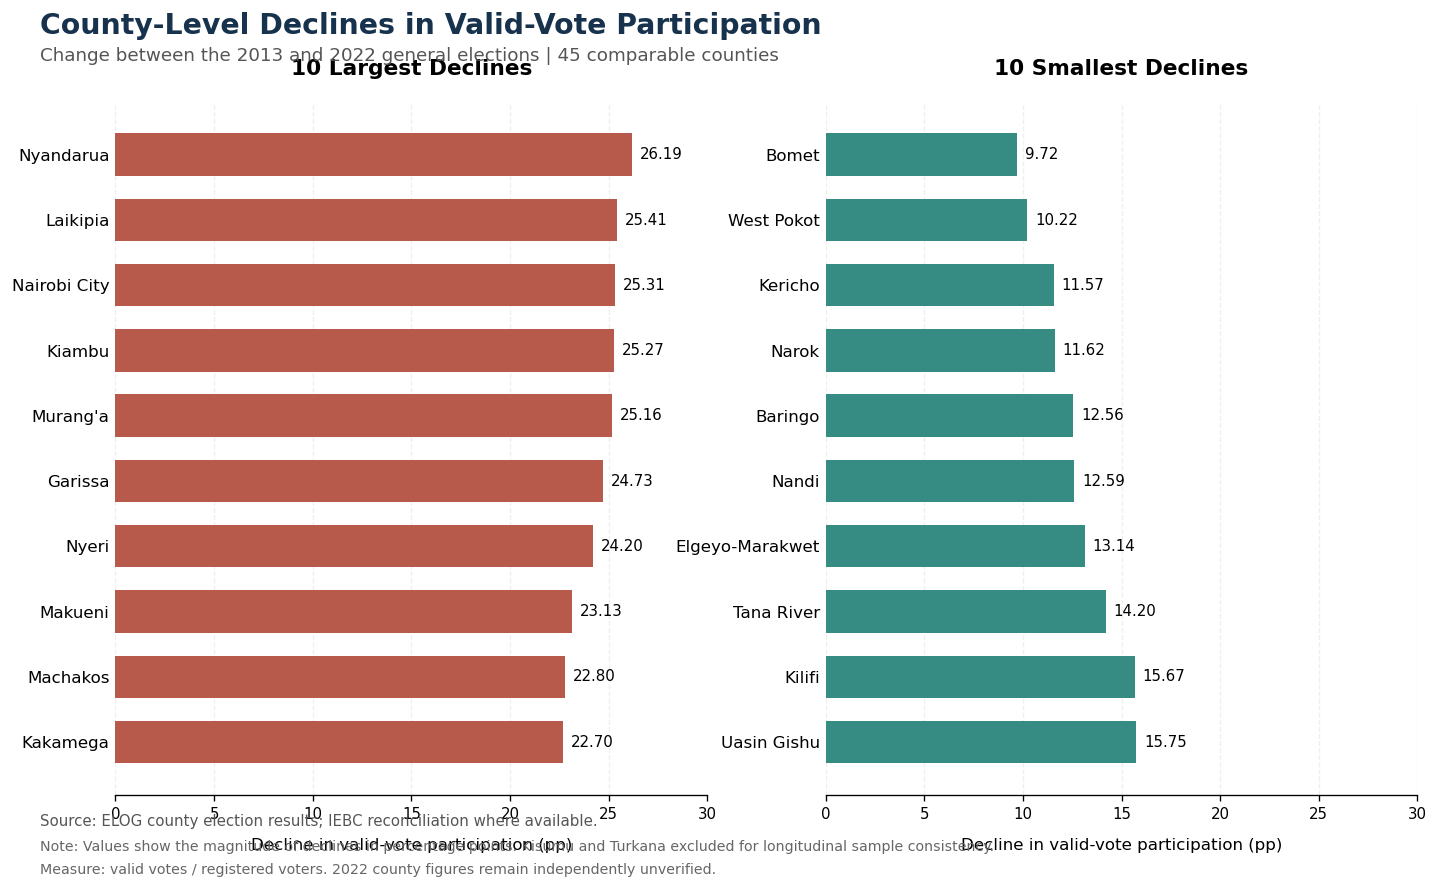


NOTEBOOK 05 — CHART 02 SAVED
File: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\reports\figures\02_county_participation_declines_2013_2022.png
File size: 362.1 KB
Export resolution: 300 DPI
Chart verification: PASSED
NOTEBOOK 05 — CELL 6 VISUALISATION COMPLETE


In [29]:

# ================================================================
# NOTEBOOK 05 — CELL 6
# CHART 02: LARGEST AND SMALLEST COUNTY PARTICIPATION DECLINES
# ================================================================
# Purpose:
# 1. Visualise the 10 largest county participation declines.
# 2. Visualise the 10 smallest county participation declines.
# 3. Use percentage-point changes, not percentage changes.
# 4. Review the chart before saving.
#
# No files are created or modified.
# ================================================================

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ------------------------------------------------
# STEP 1: PREPARE DATA
# ------------------------------------------------

largest_plot = (
    largest_declines
    .sort_values("decline_pp", ascending=True)
    .copy()
)

smallest_plot = (
    smallest_declines
    .sort_values("decline_pp", ascending=False)
    .copy()
)

# ------------------------------------------------
# STEP 2: CREATE FIGURE
# ------------------------------------------------

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 7.5),
    sharex=True
)

fig.patch.set_facecolor("white")

chart_groups = [
    (
        axes[0],
        largest_plot,
        "10 Largest Declines",
        "#B75A4B"
    ),
    (
        axes[1],
        smallest_plot,
        "10 Smallest Declines",
        "#368B83"
    )
]

# ------------------------------------------------
# STEP 3: DRAW HORIZONTAL BAR CHARTS
# ------------------------------------------------

for ax, df, title, color in chart_groups:

    bars = ax.barh(
        df["county"],
        df["decline_pp"],
        color=color,
        height=0.65
    )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=16
    )

    ax.set_xlim(0, 30)

    ax.xaxis.set_major_locator(
        mticker.MultipleLocator(5)
    )

    ax.xaxis.set_major_formatter(
        mticker.FuncFormatter(
            lambda value, pos: f"{value:.0f}"
        )
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.20
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.tick_params(
        axis="y",
        length=0,
        labelsize=10
    )

    ax.tick_params(
        axis="x",
        labelsize=9
    )

    # Add precise values to the end of each bar.
    for bar, value in zip(
        bars,
        df["decline_pp"]
    ):
        ax.text(
            bar.get_width() + 0.4,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.2f}",
            va="center",
            ha="left",
            fontsize=9,
            fontweight="medium"
        )

    ax.set_xlabel(
        "Decline in valid-vote participation (pp)",
        fontsize=10,
        labelpad=10
    )

# ------------------------------------------------
# STEP 4: ADD MAIN TITLE AND SUBTITLE
# ------------------------------------------------

fig.suptitle(
    "County-Level Declines in Valid-Vote Participation",
    x=0.08,
    y=0.98,
    ha="left",
    fontsize=17,
    fontweight="bold",
    color="#17324D"
)

fig.text(
    0.08,
    0.925,
    "Change between the 2013 and 2022 general elections | "
    "45 comparable counties",
    fontsize=11,
    color="#555555"
)

# ------------------------------------------------
# STEP 5: ADD SOURCE AND METHODOLOGY NOTES
# ------------------------------------------------

fig.text(
    0.08,
    0.075,
    "Source: ELOG county election results; "
    "IEBC reconciliation where available.",
    fontsize=9,
    color="#555555"
)

fig.text(
    0.08,
    0.048,
    "Note: Values show the magnitude of declines in percentage "
    "points. Kisumu and Turkana excluded for longitudinal "
    "sample consistency.",
    fontsize=8.5,
    color="#666666"
)

fig.text(
    0.08,
    0.022,
    "Measure: valid votes / registered voters. "
    "2022 county figures remain independently unverified.",
    fontsize=8.5,
    color="#666666"
)


# ------------------------------------------------
# STEP 6: SAVE AND DISPLAY APPROVED CHART 02
# ------------------------------------------------

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

chart02_path = (
    FIGURES_DIR
    / "02_county_participation_declines_2013_2022.png"
)

# Protect previously saved charts.
assert not chart02_path.exists(), (
    f"Chart already exists: {chart02_path}"
)

fig.savefig(
    chart02_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

assert chart02_path.is_file(), (
    "Chart 02 export failed."
)

plt.show()

print("\nNOTEBOOK 05 — CHART 02 SAVED")
print("=" * 65)
print("File:", chart02_path)
print(
    "File size:",
    f"{chart02_path.stat().st_size / 1024:.1f} KB"
)
print("Export resolution: 300 DPI")
print("Chart verification: PASSED")


print("NOTEBOOK 05 — CELL 6 VISUALISATION COMPLETE")

### Prepare registration and valid-vote growth data
This cell will calculate county-level growth rates, identify counties where valid votes decreased despite registration growth, and verify the aggregate findings.

In [36]:

# ================================================================
# NOTEBOOK 05 — CELL 7
# REGISTRATION GROWTH VS VALID-VOTE GROWTH: 2013–2022
# ================================================================
# Purpose:
# 1. Calculate county-level registration growth.
# 2. Calculate county-level valid-vote growth.
# 3. Compare growth rates across the 45-county sample.
# 4. Reproduce the aggregate findings from Notebook 04.
# 5. Identify counties with declining absolute valid votes.
#
# No files are created or modified.
# ================================================================

# ------------------------------------------------
# STEP 1: SELECT THE COMPARABLE 2013 AND 2022 DATA
# ------------------------------------------------

growth_source = general_trend_df.loc[
    general_trend_df["election_id"].isin(
        ["2013_GENERAL", "2022_GENERAL"]
    ),
    [
        "county_key",
        "county",
        "election_id",
        "analytical_registered_voters",
        "analytical_valid_votes"
    ]
].copy()

# Confirm expected sample size.
assert len(growth_source) == 90, (
    "Expected 45 counties across two elections."
)

# ------------------------------------------------
# STEP 2: RESHAPE TO COUNTY-LEVEL COMPARISON
# ------------------------------------------------

registration_wide = growth_source.pivot(
    index="county_key",
    columns="election_id",
    values="analytical_registered_voters"
).rename(
    columns={
        "2013_GENERAL": "registered_2013",
        "2022_GENERAL": "registered_2022"
    }
)

valid_votes_wide = growth_source.pivot(
    index="county_key",
    columns="election_id",
    values="analytical_valid_votes"
).rename(
    columns={
        "2013_GENERAL": "valid_votes_2013",
        "2022_GENERAL": "valid_votes_2022"
    }
)

county_names = (
    growth_source[["county_key", "county"]]
    .drop_duplicates(subset="county_key")
    .set_index("county_key")
)

growth_df = (
    county_names
    .join(registration_wide)
    .join(valid_votes_wide)
    .reset_index()
)

# ------------------------------------------------
# STEP 3: CALCULATE GROWTH RATES
# ------------------------------------------------

growth_df["registration_growth_pct"] = (
    (
        growth_df["registered_2022"]
        / growth_df["registered_2013"]
    ) - 1
) * 100

growth_df["valid_vote_growth_pct"] = (
    (
        growth_df["valid_votes_2022"]
        / growth_df["valid_votes_2013"]
    ) - 1
) * 100

growth_df["valid_vote_change_absolute"] = (
    growth_df["valid_votes_2022"]
    - growth_df["valid_votes_2013"]
)

growth_df["growth_gap_pp"] = (
    growth_df["registration_growth_pct"]
    - growth_df["valid_vote_growth_pct"]
)

# ------------------------------------------------
# STEP 4: CALCULATE AGGREGATE GROWTH
# ------------------------------------------------

registered_2013_total = growth_df[
    "registered_2013"
].sum()

registered_2022_total = growth_df[
    "registered_2022"
].sum()

valid_votes_2013_total = growth_df[
    "valid_votes_2013"
].sum()

valid_votes_2022_total = growth_df[
    "valid_votes_2022"
].sum()

aggregate_registration_growth = (
    (
        registered_2022_total
        / registered_2013_total
    ) - 1
) * 100

aggregate_valid_vote_growth = (
    (
        valid_votes_2022_total
        / valid_votes_2013_total
    ) - 1
) * 100

# ------------------------------------------------
# STEP 5: VALIDATE RESULTS
# ------------------------------------------------

assert len(growth_df) == 45, (
    "Expected 45 comparable counties."
)

assert not growth_df[
    [
        "registered_2013",
        "registered_2022",
        "valid_votes_2013",
        "valid_votes_2022"
    ]
].isna().any().any(), (
    "Missing growth comparison values detected."
)

assert growth_df["registered_2013"].gt(0).all()
assert growth_df["valid_votes_2013"].gt(0).all()

assert growth_df["registration_growth_pct"].gt(0).all(), (
    "Unexpected county registration decline."
)

assert growth_df["growth_gap_pp"].gt(0).all(), (
    "A county's valid-vote growth exceeds registration growth."
)

assert (
    growth_df["valid_vote_change_absolute"].gt(0).sum()
    == 42
), "Expected 42 counties with increased valid votes."

assert (
    growth_df["valid_vote_change_absolute"].lt(0).sum()
    == 3
), "Expected three counties with decreased valid votes."

assert abs(
    aggregate_registration_growth - 53.36
) < 0.02, (
    "Aggregate registration growth differs from Notebook 04."
)

assert abs(
    aggregate_valid_vote_growth - 15.82
) < 0.02, (
    "Aggregate valid-vote growth differs from Notebook 04."
)


# ------------------------------------------------
# STEP 6: DISPLAY FINAL ANALYTICAL RESULTS
# ------------------------------------------------

aggregate_summary = pd.DataFrame([
    {
        "Measure": "Registered voters",
        "2013": registered_2013_total,
        "2022": registered_2022_total,
        "Growth (%)": aggregate_registration_growth
    },
    {
        "Measure": "Valid votes",
        "2013": valid_votes_2013_total,
        "2022": valid_votes_2022_total,
        "Growth (%)": aggregate_valid_vote_growth
    }
])

print("REGISTRATION VS VALID-VOTE GROWTH (2013–2022)")
print("=" * 65)

display(
    aggregate_summary.style.format({
        "2013": "{:,.0f}",
        "2022": "{:,.0f}",
        "Growth (%)": "{:+.2f}%"
    })
)

# ------------------------------------------------
# STEP 7: COUNTIES WITH DECLINING VALID VOTES
# ------------------------------------------------

declining_vote_counties = (
    growth_df.loc[
        growth_df["valid_vote_change_absolute"] < 0,
        [
            "county",
            "registration_growth_pct",
            "valid_vote_growth_pct",
            "valid_vote_change_absolute"
        ]
    ]
    .sort_values("valid_vote_change_absolute")
)

print("\nCOUNTIES WITH DECLINING ABSOLUTE VALID VOTES")
print("=" * 65)

display(
    declining_vote_counties.style.format({
        "registration_growth_pct": "{:+.2f}%",
        "valid_vote_growth_pct": "{:+.2f}%",
        "valid_vote_change_absolute": "{:+,.0f}"
    })
)

# ------------------------------------------------
# STEP 8: FINAL VALIDATION CONFIRMATION
# ------------------------------------------------

print("\nVALIDATION RESULTS")
print("=" * 65)

print(f"Comparable counties: {len(growth_df)}")
print(
    "Counties where registration growth exceeded "
    "valid-vote growth:",
    growth_df["growth_gap_pp"].gt(0).sum()
)
print(
    "Counties with increased valid votes:",
    growth_df["valid_vote_change_absolute"].gt(0).sum()
)
print(
    "Counties with decreased valid votes:",
    growth_df["valid_vote_change_absolute"].lt(0).sum()
)

print("\nNOTEBOOK 05 — CELL 7 VALIDATION: PASSED")


REGISTRATION VS VALID-VOTE GROWTH (2013–2022)


,Measure,2013,2022,Growth (%)
0,Registered voters,"13,865,112","21,263,965",+53.36%
1,Valid votes,"11,770,740","13,632,612",+15.82%



COUNTIES WITH DECLINING ABSOLUTE VALID VOTES


,county,registration_growth_pct,valid_vote_growth_pct,valid_vote_change_absolute
44,Nairobi City,+39.50%,-4.23%,"-59,109"
18,Nyeri,+34.99%,-0.51%,"-1,679"
20,Murang'a,+36.87%,-0.22%,-940



VALIDATION RESULTS
Comparable counties: 45
Counties where registration growth exceeded valid-vote growth: 45
Counties with increased valid votes: 42
Counties with decreased valid votes: 3

NOTEBOOK 05 — CELL 7 VALIDATION: PASSED


**We can now visualise the difference between registered-voter growth and valid-vote growth.**

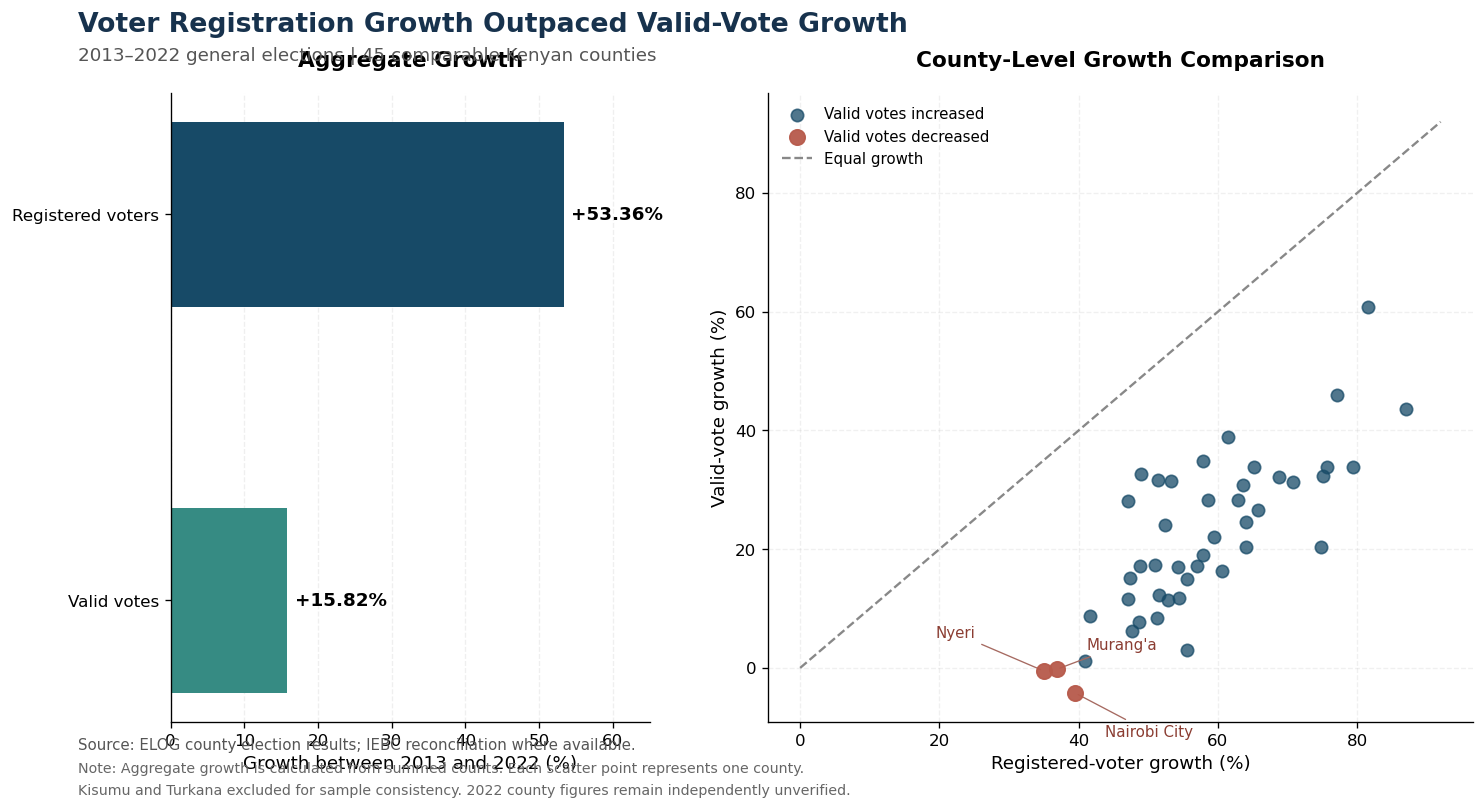


NOTEBOOK 05 — CHART 03 SAVED
File: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\reports\figures\03_registration_vs_valid_vote_growth_2013_2022.png
File size: 439.1 KB
Export resolution: 300 DPI
Chart verification: PASSED


In [43]:

# ================================================================
# NOTEBOOK 05 — CELL 8
# CHART 03: REGISTRATION GROWTH VS VALID-VOTE GROWTH
# ================================================================
# Purpose:
# 1. Compare aggregate registration and valid-vote growth.
# 2. Visualise county-level growth differences.
# 3. Highlight counties with declining absolute valid votes.
# 4. Review chart before saving.
#
# No files are created or modified.
# ================================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------
# STEP 1: VALIDATE CHART INPUTS
# ------------------------------------------------

assert len(growth_df) == 45
assert growth_df["growth_gap_pp"].gt(0).all()

assert abs(
    aggregate_registration_growth - 53.36
) < 0.02

assert abs(
    aggregate_valid_vote_growth - 15.82
) < 0.02

# ------------------------------------------------
# STEP 2: CREATE FIGURE
# ------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6.8),
    gridspec_kw={"width_ratios": [0.85, 1.25]}
)

fig.patch.set_facecolor("white")

# ------------------------------------------------
# STEP 3: LEFT PANEL — AGGREGATE GROWTH
# ------------------------------------------------

ax1 = axes[0]

measures = [
    "Registered voters",
    "Valid votes"
]

growth_values = [
    aggregate_registration_growth,
    aggregate_valid_vote_growth
]

bar_colors = [
    "#174A67",
    "#368B83"
]

bars = ax1.barh(
    measures,
    growth_values,
    color=bar_colors,
    height=0.48
)

ax1.invert_yaxis()

ax1.set_xlim(0, 65)

ax1.set_title(
    "Aggregate Growth",
    fontsize=13,
    fontweight="bold",
    pad=16
)

ax1.set_xlabel(
    "Growth between 2013 and 2022 (%)"
)

ax1.grid(
    axis="x",
    linestyle="--",
    alpha=0.2
)

ax1.set_axisbelow(True)

for bar, value in zip(bars, growth_values):
    ax1.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"+{value:.2f}%",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

# ------------------------------------------------
# STEP 4: RIGHT PANEL — COUNTY GROWTH COMPARISON
# ------------------------------------------------

ax2 = axes[1]

positive_votes = growth_df[
    growth_df["valid_vote_growth_pct"] >= 0
]

negative_votes = growth_df[
    growth_df["valid_vote_growth_pct"] < 0
]

ax2.scatter(
    positive_votes["registration_growth_pct"],
    positive_votes["valid_vote_growth_pct"],
    s=55,
    color="#174A67",
    alpha=0.75,
    label="Valid votes increased"
)

ax2.scatter(
    negative_votes["registration_growth_pct"],
    negative_votes["valid_vote_growth_pct"],
    s=85,
    color="#B75A4B",
    alpha=0.95,
    label="Valid votes decreased",
    zorder=4
)

# Reference line: equal growth rates.
reference_max = max(
    growth_df["registration_growth_pct"].max(),
    growth_df["valid_vote_growth_pct"].max()
) + 5

ax2.plot(
    [0, reference_max],
    [0, reference_max],
    linestyle="--",
    linewidth=1.4,
    color="#888888",
    label="Equal growth"
)


# ------------------------------------------------
# IMPROVED ANNOTATIONS FOR COUNTIES WITH DECLINING VOTES
# ------------------------------------------------

# Use different offsets to prevent overlapping labels.
annotation_offsets = {
    "Nairobi City": (18, -26),
    "Nyeri": (-65, 20),
    "Murang'a": (18, 12)
}

for _, row in negative_votes.iterrows():

    county = row["county"]

    offset = annotation_offsets.get(
        county,
        (10, 10)
    )

    ax2.annotate(
        county,
        xy=(
            row["registration_growth_pct"],
            row["valid_vote_growth_pct"]
        ),
        xytext=offset,
        textcoords="offset points",
        fontsize=9,
        fontweight="medium",
        color="#8B3D32",
        arrowprops={
            "arrowstyle": "-",
            "color": "#A66A61",
            "linewidth": 0.8
        },
        annotation_clip=False
    )


ax2.set_title(
    "County-Level Growth Comparison",
    fontsize=13,
    fontweight="bold",
    pad=16
)

ax2.set_xlabel("Registered-voter growth (%)")
ax2.set_ylabel("Valid-vote growth (%)")

ax2.grid(
    linestyle="--",
    alpha=0.18
)

ax2.set_axisbelow(True)

ax2.legend(
    loc="upper left",
    fontsize=9,
    frameon=False
)

# ------------------------------------------------
# STEP 5: CONSISTENT AXIS STYLING
# ------------------------------------------------

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ------------------------------------------------
# STEP 6: TITLE AND SOURCE NOTES
# ------------------------------------------------

fig.suptitle(
    "Voter Registration Growth Outpaced Valid-Vote Growth",
    x=0.07,
    y=0.98,
    ha="left",
    fontsize=16,
    fontweight="bold",
    color="#17324D"
)

fig.text(
    0.07,
    0.92,
    "2013–2022 general elections | 45 comparable Kenyan counties",
    fontsize=11,
    color="#555555"
)

fig.text(
    0.07,
    0.075,
    "Source: ELOG county election results; "
    "IEBC reconciliation where available.",
    fontsize=9,
    color="#555555"
)

fig.text(
    0.07,
    0.047,
    "Note: Aggregate growth is calculated from summed counts. "
    "Each scatter point represents one county.",
    fontsize=8.5,
    color="#666666"
)

fig.text(
    0.07,
    0.020,
    "Kisumu and Turkana excluded for sample consistency. "
    "2022 county figures remain independently unverified.",
    fontsize=8.5,
    color="#666666"
)


# ------------------------------------------------
# STEP 7: SAVE AND DISPLAY CHART 03
# ------------------------------------------------

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

chart03_path = (
    FIGURES_DIR
    / "03_registration_vs_valid_vote_growth_2013_2022.png"
)

# Prevent accidental overwriting.
assert not chart03_path.exists(), (
    f"Chart already exists: {chart03_path}"
)

fig.savefig(
    chart03_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

assert chart03_path.is_file(), (
    "Chart 03 export failed."
)

plt.show()

print("\nNOTEBOOK 05 — CHART 03 SAVED")
print("=" * 65)
print("File:", chart03_path)
print(
    "File size:",
    f"{chart03_path.stat().st_size / 1024:.1f} KB"
)
print("Export resolution: 300 DPI")
print("Chart verification: PASSED")


**Analytical finding to retain**

Across the 45 comparable counties between 2013 and 2022:
- Registered voters increased by 53.36%.
- Valid votes increased by 15.82%.
- The difference between these growth rates was 37.54 percentage points.
- All 45 counties recorded registration growth exceeding valid-vote growth.
- Nairobi City, Nyeri and Murang'a recorded declines in absolute valid votes.
  
The findings highlight a distinction between expanding the voter register and translating that expansion into valid votes. They do not, on their own, establish why participation changed.

### Prepare August–October 2017 turnout comparisons
This cell will prepare the data for our fourth chart, identify the counties with the largest and smallest turnout declines, and verify the earlier findings.

In [49]:

# ================================================================
# NOTEBOOK 05 — CELL 9
# AUGUST VS OCTOBER 2017 TURNOUT COMPARISON
# ================================================================
# Purpose:
# 1. Compare calculated turnout across the two 2017 elections.
# 2. Use the 45 counties with comparable turnout data.
# 3. Calculate turnout changes in percentage points.
# 4. Identify the largest and smallest county declines.
# 5. Validate the findings before visualisation.
#
# No files are created or modified.
# ================================================================

# ------------------------------------------------
# STEP 1: SELECT THE TWO 2017 ELECTION EVENTS
# ------------------------------------------------

turnout_source = elections_df.loc[
    elections_df["election_id"].isin([
        "2017_AUG_GENERAL",
        "2017_OCT_FRESH"
    ]),
    [
        "county_key",
        "county",
        "election_id",
        "analytical_registered_voters",
        "analytical_ballots_cast",
        "calculated_turnout_pct"
    ]
].copy()

# ------------------------------------------------
# STEP 2: IDENTIFY COMPARABLE COUNTIES
# ------------------------------------------------

august_turnout_counties = set(
    turnout_source.loc[
        (turnout_source["election_id"] == "2017_AUG_GENERAL")
        & turnout_source["calculated_turnout_pct"].notna(),
        "county_key"
    ]
)

october_turnout_counties = set(
    turnout_source.loc[
        (turnout_source["election_id"] == "2017_OCT_FRESH")
        & turnout_source["calculated_turnout_pct"].notna(),
        "county_key"
    ]
)

comparable_2017_counties = (
    august_turnout_counties
    & october_turnout_counties
)

assert len(comparable_2017_counties) == 45, (
    "Expected 45 comparable counties."
)

# ------------------------------------------------
# STEP 3: FILTER AND RESHAPE DATA
# ------------------------------------------------

turnout_comparison = turnout_source.loc[
    turnout_source["county_key"].isin(
        comparable_2017_counties
    )
].copy()

turnout_wide = (
    turnout_comparison
    .pivot(
        index="county_key",
        columns="election_id",
        values="calculated_turnout_pct"
    )
    .rename(columns={
        "2017_AUG_GENERAL": "august_turnout_pct",
        "2017_OCT_FRESH": "october_turnout_pct"
    })
    .reset_index()
)

county_names = (
    turnout_comparison[["county_key", "county"]]
    .drop_duplicates(subset="county_key")
)

turnout_wide = turnout_wide.merge(
    county_names,
    on="county_key",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------
# STEP 4: CALCULATE TURNOUT CHANGES
# ------------------------------------------------

turnout_wide["turnout_change_pp"] = (
    turnout_wide["october_turnout_pct"]
    - turnout_wide["august_turnout_pct"]
)

turnout_wide["turnout_decline_pp"] = (
    -turnout_wide["turnout_change_pp"]
)

# ------------------------------------------------
# STEP 5: VALIDATE RESULTS
# ------------------------------------------------

assert len(turnout_wide) == 45

assert not turnout_wide[
    [
        "august_turnout_pct",
        "october_turnout_pct",
        "turnout_change_pp"
    ]
].isna().any().any(), (
    "Missing comparable turnout values."
)

assert turnout_wide[
    "turnout_change_pp"
].lt(0).all(), (
    "Unexpected county turnout increase detected."
)

# ------------------------------------------------
# STEP 6: IDENTIFY LARGEST AND SMALLEST DECLINES
# ------------------------------------------------

largest_2017_declines = (
    turnout_wide
    .sort_values("turnout_decline_pp", ascending=False)
    .head(10)
)

smallest_2017_declines = (
    turnout_wide
    .sort_values("turnout_decline_pp", ascending=True)
    .head(10)
)

display_columns = [
    "county",
    "august_turnout_pct",
    "october_turnout_pct",
    "turnout_change_pp"
]

# ------------------------------------------------
# STEP 7: DISPLAY RESULTS
# ------------------------------------------------

print("AUGUST–OCTOBER 2017 TURNOUT COMPARISON")
print("=" * 65)

print("\n10 COUNTIES WITH THE LARGEST TURNOUT DECLINES")

display(
    largest_2017_declines[
        display_columns
    ].round(2)
)

print("\n10 COUNTIES WITH THE SMALLEST TURNOUT DECLINES")

display(
    smallest_2017_declines[
        display_columns
    ].round(2)
)

print("\nSUMMARY")

print("Comparable counties:", len(turnout_wide))

print(
    "Counties with declining turnout:",
    turnout_wide["turnout_change_pp"].lt(0).sum()
)

print(
    "Mean county turnout decline:",
    f"{turnout_wide['turnout_decline_pp'].mean():.2f} pp"
)

print(
    "Median county turnout decline:",
    f"{turnout_wide['turnout_decline_pp'].median():.2f} pp"
)

print(
    "Largest turnout decline:",
    f"{turnout_wide['turnout_decline_pp'].max():.2f} pp"
)

print(
    "Smallest turnout decline:",
    f"{turnout_wide['turnout_decline_pp'].min():.2f} pp"
)

print("\nNOTEBOOK 05 — CELL 9 VALIDATION: PASSED")


AUGUST–OCTOBER 2017 TURNOUT COMPARISON

10 COUNTIES WITH THE LARGEST TURNOUT DECLINES


,county,august_turnout_pct,october_turnout_pct,turnout_change_pp
7,Homa Bay,84.71,0.00,-84.71
36,Siaya,83.02,0.00,-83.02
25,Migori,83.20,8.64,-74.56
21,Makueni,78.85,4.64,-74.21
3,Busia,79.16,6.78,-72.38
42,Vihiga,74.14,3.98,-70.16
10,Kakamega,74.94,6.01,-68.93
16,Kitui,76.36,10.70,-65.66
20,Machakos,76.24,10.93,-65.31
22,Mandera,77.36,14.16,-63.20



10 COUNTIES WITH THE SMALLEST TURNOUT DECLINES


,county,august_turnout_pct,october_turnout_pct,turnout_change_pp
27,Murang'a,86.88,85.17,-1.71
34,Nyeri,86.82,84.23,-2.59
33,Nyandarua,86.56,83.81,-2.75
14,Kirinyaga,87.15,84.36,-2.79
12,Kiambu,83.74,78.81,-4.93
11,Kericho,78.64,73.17,-5.47
4,Elgeyo-Marakwet,81.35,70.98,-10.37
29,Nakuru,79.91,69.24,-10.67
18,Laikipia,81.21,70.41,-10.80
5,Embu,81.69,70.65,-11.04



SUMMARY
Comparable counties: 45
Counties with declining turnout: 45
Mean county turnout decline: 39.09 pp
Median county turnout decline: 44.82 pp
Largest turnout decline: 84.71 pp
Smallest turnout decline: 1.71 pp

NOTEBOOK 05 — CELL 9 VALIDATION: PASSED


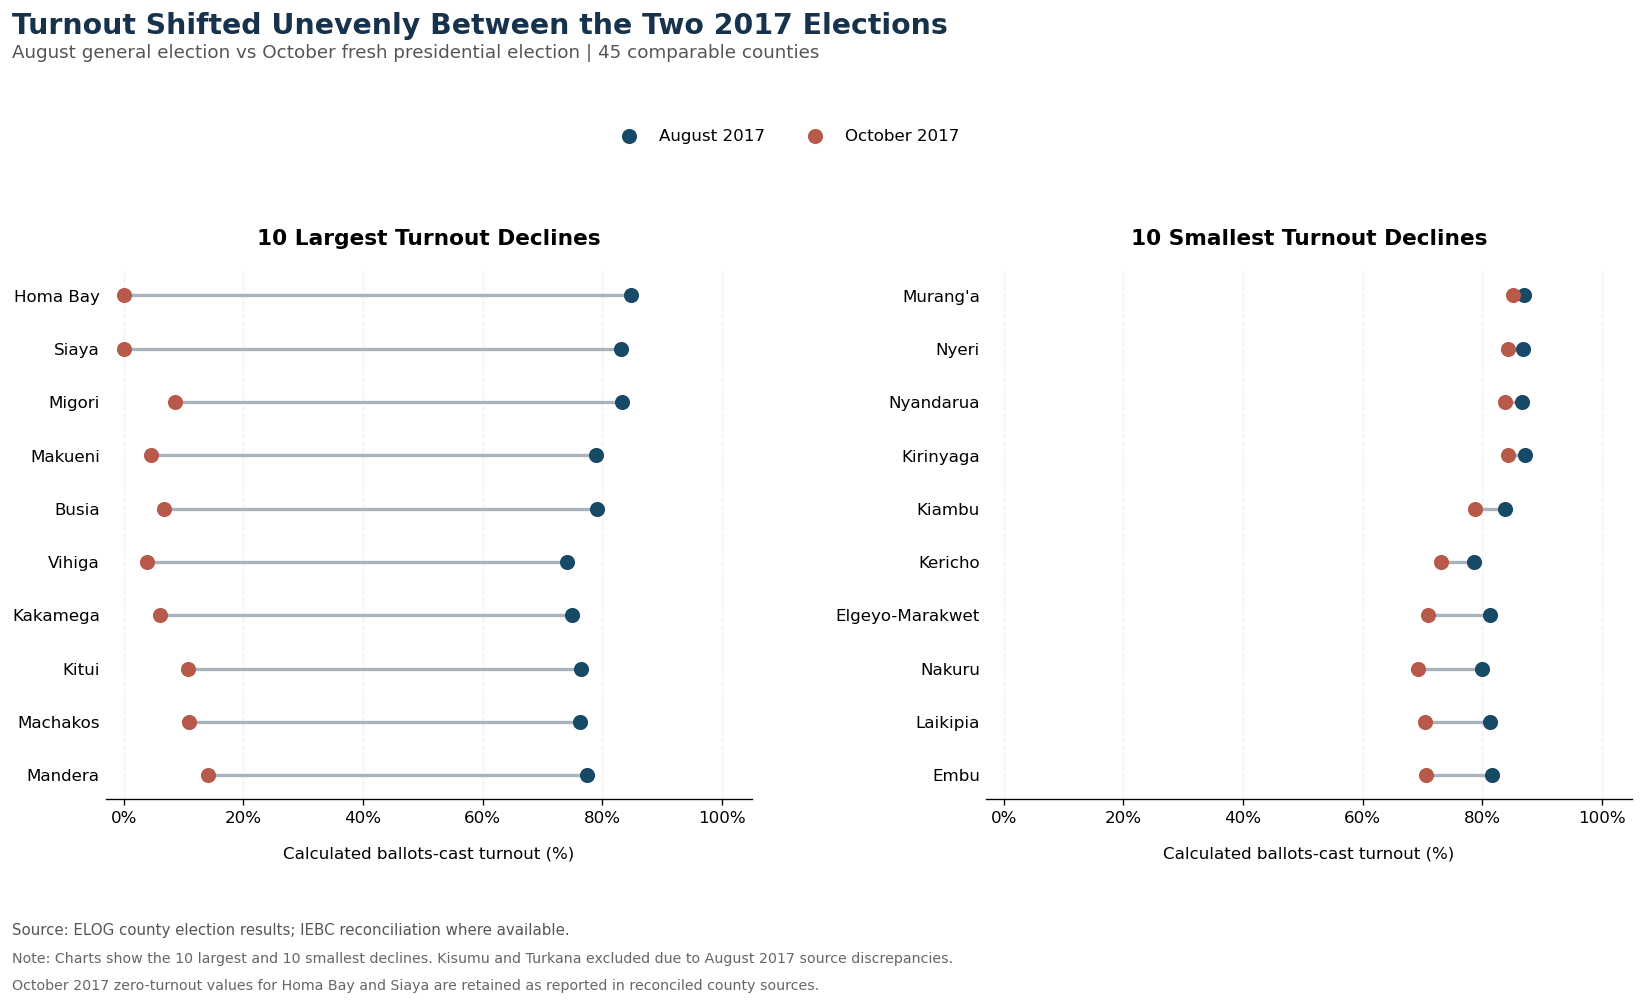


NOTEBOOK 05 — CHART 04 SAVED
File: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\reports\figures\04_august_october_2017_county_turnout_comparison.png
File size: 364.1 KB
Export resolution: 300 DPI
Chart verification: PASSED


In [54]:

# ================================================================
# NOTEBOOK 05 — CELL 10
# CHART 04: AUGUST VS OCTOBER 2017 COUNTY TURNOUT
# ================================================================
# Purpose:
# 1. Visualise turnout changes between August and October 2017.
# 2. Compare the 10 largest and 10 smallest county declines.
# 3. Show both election turnout levels, not just the difference.
# 4. Preserve the distinction between general and fresh elections.
#
# The chart is displayed only; no files are saved yet.
# ================================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------
# STEP 1: PREPARE CHART DATA
# ------------------------------------------------

largest_2017_plot = (
    largest_2017_declines
    .sort_values("turnout_decline_pp", ascending=False)
    .copy()
)

smallest_2017_plot = (
    smallest_2017_declines
    .sort_values("turnout_decline_pp", ascending=True)
    .copy()
)

# ------------------------------------------------
# STEP 2: CREATE FIGURE
# ------------------------------------------------

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 8.5),
    sharex=True
)

fig.patch.set_facecolor("white")

chart_groups = [
    (
        axes[0],
        largest_2017_plot,
        "10 Largest Turnout Declines"
    ),
    (
        axes[1],
        smallest_2017_plot,
        "10 Smallest Turnout Declines"
    )
]

# ------------------------------------------------
# STEP 3: DRAW COUNTY TURNOUT SLOPES
# ------------------------------------------------

for ax, df, title in chart_groups:

    df = df.reset_index(drop=True)
    y_positions = np.arange(len(df))

    august = df["august_turnout_pct"].to_numpy()
    october = df["october_turnout_pct"].to_numpy()

    # Draw a connecting line for each county.
    for i in range(len(df)):
        ax.plot(
            [october[i], august[i]],
            [y_positions[i], y_positions[i]],
            color="#AAB4BE",
            linewidth=2,
            zorder=1
        )

    # August 2017 markers.
    ax.scatter(
        august,
        y_positions,
        color="#174A67",
        s=65,
        zorder=3,
        label="August 2017"
    )

    # October 2017 markers.
    ax.scatter(
        october,
        y_positions,
        color="#B75A4B",
        s=65,
        zorder=3,
        label="October 2017"
    )

    # Label each county.
    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        df["county"],
        fontsize=10
    )

    # First county appears at the top.
    ax.invert_yaxis()

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=16
    )

    ax.set_xlim(-3, 105)
    ax.set_xticks(
        np.arange(0, 101, 20)
    )

    ax.set_xticklabels(
        [f"{value}%" for value in range(0, 101, 20)]
    )

    ax.set_xlabel(
        "Calculated ballots-cast turnout (%)",
        fontsize=10,
        labelpad=12
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.20
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis="y",
        length=0
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

# ------------------------------------------------
# STEP 4: ADD SHARED LEGEND
# ------------------------------------------------

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.88),
    ncol=2,
    frameon=False,
    fontsize=10
)

# ------------------------------------------------
# STEP 5: ADD TITLE AND METHODOLOGY NOTES
# ------------------------------------------------

fig.suptitle(
    "Turnout Shifted Unevenly Between the Two 2017 Elections",
    x=0.07,
    y=0.98,
    ha="left",
    fontsize=17,
    fontweight="bold",
    color="#17324D"
)

fig.text(
    0.07,
    0.935,
    "August general election vs October fresh presidential election "
    "| 45 comparable counties",
    fontsize=11,
    color="#555555"
)

fig.text(
    0.07,
    0.075,
    "Source: ELOG county election results; "
    "IEBC reconciliation where available.",
    fontsize=9,
    color="#555555"
)

fig.text(
    0.07,
    0.048,
    "Note: Charts show the 10 largest and 10 smallest declines. "
    "Kisumu and Turkana excluded due to August 2017 source discrepancies.",
    fontsize=8.5,
    color="#666666"
)

fig.text(
    0.07,
    0.021,
    "October 2017 zero-turnout values for Homa Bay and Siaya "
    "are retained as reported in reconciled county sources.",
    fontsize=8.5,
    color="#666666"
)

# ------------------------------------------------
# STEP 6: ADJUST LAYOUT AND DISPLAY
# ------------------------------------------------

plt.tight_layout(
    rect=[0.06, 0.13, 0.98, 0.83],
    w_pad=5
)


# ------------------------------------------------
# STEP 7: SAVE AND DISPLAY APPROVED CHART 04
# ------------------------------------------------

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

chart04_path = (
    FIGURES_DIR
    / "04_august_october_2017_county_turnout_comparison.png"
)

# Protect previously saved chart files.
assert not chart04_path.exists(), (
    f"Chart already exists: {chart04_path}"
)

fig.savefig(
    chart04_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

assert chart04_path.is_file(), (
    "Chart 04 export failed."
)

plt.show()

print("\nNOTEBOOK 05 — CHART 04 SAVED")
print("=" * 65)
print("File:", chart04_path)
print(
    "File size:",
    f"{chart04_path.stat().st_size / 1024:.1f} KB"
)
print("Export resolution: 300 DPI")
print("Chart verification: PASSED")



The difference between the two panels is striking. It demonstrates that the decline was widespread but far from uniform.

The zero-turnout values for Homa Bay and Siaya remain explicitly documented as reconciled source values, which is important for transparency.

### Classify turnout declines
In Notebook 04, we established four categories of turnout decline. Rather than introducing a new classification, we will reproduce the same thresholds and validate the results against our earlier findings.

In [57]:

# ================================================================
# NOTEBOOK 05 — CELL 11
# CLASSIFY AUGUST–OCTOBER 2017 TURNOUT DECLINES
# ================================================================
# Purpose:
# 1. Reproduce the decline categories from Notebook 04.
# 2. Classify all 45 comparable counties.
# 3. Calculate county and registered-voter shares.
# 4. Validate the results against previous findings.
#
# No files are created or modified.
# ================================================================

import pandas as pd
import numpy as np

# ------------------------------------------------
# STEP 1: PREPARE COUNTY-LEVEL TURNOUT DATA
# ------------------------------------------------

decline_classification_df = turnout_wide.copy()

# Add August 2017 registered-voter counts.
august_registration = (
    elections_df.loc[
        elections_df["election_id"] == "2017_AUG_GENERAL",
        [
            "county_key",
            "analytical_registered_voters"
        ]
    ]
    .rename(columns={
        "analytical_registered_voters": "registered_voters"
    })
)

decline_classification_df = (
    decline_classification_df
    .merge(
        august_registration,
        on="county_key",
        how="left",
        validate="one_to_one"
    )
)

# ------------------------------------------------
# STEP 2: DEFINE DECLINE CATEGORIES
# ------------------------------------------------

# Use unrounded percentage-point declines.
# Rounding before classification can change
# a county's category near a threshold.

category_bins = [
    -np.inf,
    15,
    40,
    65,
    np.inf
]

category_labels = [
    "Limited decline",
    "Moderate decline",
    "Large decline",
    "Severe decline"
]

decline_classification_df["decline_category"] = pd.cut(
    decline_classification_df["turnout_decline_pp"],
    bins=category_bins,
    labels=category_labels,
    right=False
)

# ------------------------------------------------
# STEP 3: AGGREGATE CATEGORY RESULTS
# ------------------------------------------------

decline_category_summary = (
    decline_classification_df
    .groupby(
        "decline_category",
        observed=True
    )
    .agg(
        counties=("county_key", "nunique"),
        registered_voters=("registered_voters", "sum"),
        mean_decline_pp=("turnout_decline_pp", "mean"),
        median_decline_pp=("turnout_decline_pp", "median")
    )
    .reset_index()
)

# ------------------------------------------------
# STEP 4: CALCULATE SHARES
# ------------------------------------------------

total_counties = decline_category_summary[
    "counties"
].sum()

total_registered = decline_category_summary[
    "registered_voters"
].sum()

decline_category_summary["county_share_pct"] = (
    decline_category_summary["counties"]
    / total_counties
    * 100
)

decline_category_summary["registered_voter_share_pct"] = (
    decline_category_summary["registered_voters"]
    / total_registered
    * 100
)

# ------------------------------------------------
# STEP 5: VALIDATE RESULTS
# ------------------------------------------------

assert len(decline_classification_df) == 45

assert decline_classification_df[
    "decline_category"
].notna().all(), (
    "One or more counties could not be classified."
)

assert decline_classification_df[
    "registered_voters"
].notna().all(), (
    "Missing registered-voter counts."
)

assert total_counties == 45

assert total_registered == 18_876_036, (
    "Unexpected August 2017 registered-voter total."
)

expected_category_counts = {
    "Limited decline": 14,
    "Moderate decline": 6,
    "Large decline": 16,
    "Severe decline": 9
}

actual_category_counts = dict(
    zip(
        decline_category_summary[
            "decline_category"
        ].astype(str),
        decline_category_summary["counties"]
    )
)

assert actual_category_counts == expected_category_counts, (
    f"Category counts differ from Notebook 04: "
    f"{actual_category_counts}"
)

assert np.isclose(
    decline_category_summary["county_share_pct"].sum(),
    100
)

assert np.isclose(
    decline_category_summary[
        "registered_voter_share_pct"
    ].sum(),
    100
)

# ------------------------------------------------
# STEP 6: DISPLAY RESULTS
# ------------------------------------------------

print("AUGUST–OCTOBER 2017 TURNOUT DECLINE CLASSIFICATION")
print("=" * 65)

display(
    decline_category_summary.style.format({
        "registered_voters": "{:,.0f}",
        "mean_decline_pp": "{:.2f}",
        "median_decline_pp": "{:.2f}",
        "county_share_pct": "{:.2f}%",
        "registered_voter_share_pct": "{:.2f}%"
    })
)

print("\nVALIDATION SUMMARY")
print("=" * 65)

print("Comparable counties:", total_counties)
print("Registered voters represented:", f"{total_registered:,}")
print("Decline categories:", len(decline_category_summary))

print("\nNOTEBOOK 05 — CELL 11 VALIDATION: PASSED")


AUGUST–OCTOBER 2017 TURNOUT DECLINE CLASSIFICATION


,decline_category,counties,registered_voters,mean_decline_pp,median_decline_pp,county_share_pct,registered_voter_share_pct
0,Limited decline,14,"6,557,985",8.25,10.52,31.11%,34.74%
1,Moderate decline,6,"3,595,700",31.04,37.59,13.33%,19.05%
2,Large decline,16,"4,512,971",49.88,47.07,35.56%,23.91%
3,Severe decline,9,"4,209,380",73.22,72.38,20.00%,22.30%



VALIDATION SUMMARY
Comparable counties: 45
Registered voters represented: 18,876,036
Decline categories: 4

NOTEBOOK 05 — CELL 11 VALIDATION: PASSED


Together, the large and severe categories account for 25 of 45 counties (55.56%) and approximately 46.21% of registered voters in the comparable sample.

These categories describe the magnitude of turnout changes; they do not establish the reasons for those changes.

The distinction between county share and registered-voter share is particularly interesting.

For example, counties experiencing large declines account for 35.56% of counties, but only 23.91% of registered voters. This means their average registered electorate was smaller than that of counties in some other categories.

Conversely, the six counties experiencing moderate declines account for only 13.33% of counties but 19.05% of registered voters.

These figures represent registered voters living in counties within each category—not the number of voters who abstained.

***We'll create a grouped horizontal bar chart comparing the percentage of counties with the percentage of registered voters in each decline category.***

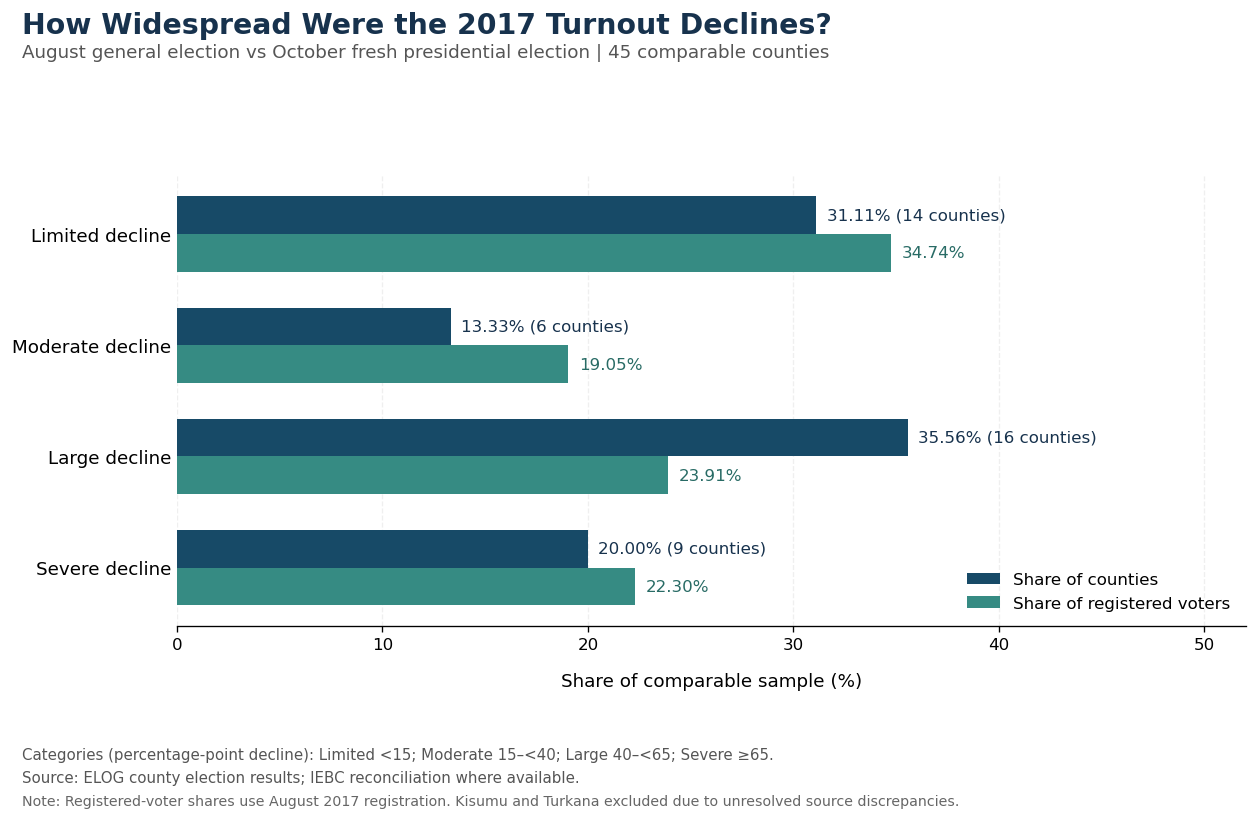


NOTEBOOK 05 — CHART 05 SAVED
File: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\reports\figures\05_august_october_2017_turnout_decline_distribution.png
File size: 310.6 KB
Export resolution: 300 DPI
Chart verification: PASSED


In [66]:

# ================================================================
# NOTEBOOK 05 — CELL 12
# CHART 05: DISTRIBUTION OF 2017 TURNOUT DECLINES
# ================================================================
# Purpose:
# 1. Compare county shares across turnout-decline categories.
# 2. Compare registered-voter shares across the same categories.
# 3. Highlight differences between geographical and voter shares.
# 4. Review chart before saving.
#
# No files are created or modified.
# ================================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------
# STEP 1: PREPARE CHART DATA
# ------------------------------------------------

chart05_df = decline_category_summary.copy()

categories = chart05_df[
    "decline_category"
].astype(str).tolist()

county_shares = chart05_df[
    "county_share_pct"
].to_numpy()

voter_shares = chart05_df[
    "registered_voter_share_pct"
].to_numpy()

county_counts = chart05_df[
    "counties"
].to_numpy()

# ------------------------------------------------
# STEP 2: CREATE FIGURE
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(11.5, 7))

fig.patch.set_facecolor("white")

y = np.arange(len(categories))
bar_height = 0.34

# ------------------------------------------------
# STEP 3: DRAW GROUPED HORIZONTAL BARS
# ------------------------------------------------

county_bars = ax.barh(
    y - bar_height / 2,
    county_shares,
    height=bar_height,
    color="#174A67",
    label="Share of counties"
)

voter_bars = ax.barh(
    y + bar_height / 2,
    voter_shares,
    height=bar_height,
    color="#368B83",
    label="Share of registered voters"
)

# ------------------------------------------------
# STEP 4: ADD VALUE LABELS
# ------------------------------------------------

for bar, value, count in zip(
    county_bars,
    county_shares,
    county_counts
):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}% ({count} counties)",
        va="center",
        fontsize=10,
        color="#17324D"
    )

for bar, value in zip(
    voter_bars,
    voter_shares
):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=10,
        color="#286B65"
    )

# ------------------------------------------------
# STEP 5: FORMAT AXES
# ------------------------------------------------

ax.set_yticks(y)
ax.set_yticklabels(
    categories,
    fontsize=11
)

ax.invert_yaxis()

ax.set_xlim(0, 52)

ax.set_xlabel(
    "Share of comparable sample (%)",
    fontsize=11,
    labelpad=12
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.20
)

ax.set_axisbelow(True)

ax.tick_params(axis="y", length=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

# ------------------------------------------------
# STEP 6: ADD LEGEND
# ------------------------------------------------

ax.legend(
    loc="lower right",
    frameon=False,
    fontsize=10
)

# ------------------------------------------------
# STEP 7: ADD TITLE AND METHODOLOGY NOTES
# ------------------------------------------------

fig.suptitle(
    "How Widespread Were the 2017 Turnout Declines?",
    x=0.08,
    y=0.97,
    ha="left",
    fontsize=17,
    fontweight="bold",
    color="#17324D"
)

fig.text(
    0.08,
    0.915,
    "August general election vs October fresh presidential election "
    "| 45 comparable counties",
    fontsize=11,
    color="#555555"
)

fig.text(
    0.08,
    0.080,
    "Categories (percentage-point decline): Limited <15; "
    "Moderate 15–<40; Large 40–<65; Severe ≥65.",
    fontsize=9,
    color="#555555"
)

fig.text(
    0.08,
    0.052,
    "Source: ELOG county election results; "
    "IEBC reconciliation where available.",
    fontsize=9,
    color="#555555"
)

fig.text(
    0.08,
    0.025,
    "Note: Registered-voter shares use August 2017 registration. "
    "Kisumu and Turkana excluded due to unresolved source discrepancies.",
    fontsize=8.5,
    color="#666666"
)

# ------------------------------------------------
# STEP 8: ADJUST LAYOUT AND DISPLAY
# ------------------------------------------------

plt.tight_layout(
    rect=[0.06, 0.14, 0.98, 0.85]
)


# ------------------------------------------------
# STEP 9: SAVE AND DISPLAY APPROVED CHART 05
# ------------------------------------------------

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

chart05_path = (
    FIGURES_DIR
    / "05_august_october_2017_turnout_decline_distribution.png"
)

# Prevent accidental overwriting.
assert not chart05_path.exists(), (
    f"Chart already exists: {chart05_path}"
)

fig.savefig(
    chart05_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

assert chart05_path.is_file(), (
    "Chart 05 export failed."
)

plt.show()

print("\nNOTEBOOK 05 — CHART 05 SAVED")
print("=" * 65)
print("File:", chart05_path)
print(
    "File size:",
    f"{chart05_path.stat().st_size / 1024:.1f} KB"
)
print("Export resolution: 300 DPI")
print("Chart verification: PASSED")



### Main findings established
Our visualisations support five central findings:

**1. Valid-vote participation declined:** From 84.89% in 2013 to 64.11% in 2022 across the 45 comparable counties, a decline of 20.78 percentage points.

**2. The decline was widespread but uneven:** All 45 counties recorded lower valid-vote participation in 2022 than in 2013. Nyandarua experienced the largest decline (26.19 pp), while Bomet experienced the smallest (9.72 pp).

**3. Registration growth outpaced valid-vote growth:** Registered voters increased by 53.36%, compared with 15.82% growth in valid votes.

**4. The October 2017 fresh election showed substantial turnout differences:** All 45 comparable counties recorded lower turnout than in August 2017, with a mean county decline of 39.09 percentage points.

**5. Large or severe 2017 turnout declines affected most counties in the sample:** These categories accounted for 25 of 45 counties (55.56%), representing 46.21% of registered voters.

These are descriptive findings. Our analysis does not establish the causes of the observed participation changes.

### Final reporting validation
Before drafting the report, I recommend one final checkpoint to verify that all five chart files exist, that the analytical sample remains consistent, and that our principal findings agree with the calculations.

This will also help us document the outputs for reproducibility.

In [71]:

# ================================================================
# NOTEBOOK 05 — CELL 13
# FINAL VISUALISATION AND ANALYTICAL VALIDATION
# ================================================================
# Purpose:
# 1. Verify that all five approved charts exist.
# 2. Confirm the principal analytical findings.
# 3. Check the 45-county comparison samples.
# 4. Prepare a validation summary for reporting.
#
# No files are created or modified.
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------
# STEP 1: VERIFY SAVED CHARTS
# ------------------------------------------------

chart_files = {
    "Chart 01 — General-election participation":
        "01_general_election_valid_vote_participation.png",

    "Chart 02 — County participation declines":
        "02_county_participation_declines_2013_2022.png",

    "Chart 03 — Registration vs valid-vote growth":
        "03_registration_vs_valid_vote_growth_2013_2022.png",

    "Chart 04 — August–October 2017 turnout":
        "04_august_october_2017_county_turnout_comparison.png",

    "Chart 05 — Turnout decline distribution":
        "05_august_october_2017_turnout_decline_distribution.png"
}

chart_checks = pd.DataFrame([
    {
        "chart": name,
        "status": "PASS" if (FIGURES_DIR / filename).is_file()
                  else "FAIL",
        "file_size_kb": round(
            (FIGURES_DIR / filename).stat().st_size / 1024, 1
        ) if (FIGURES_DIR / filename).is_file() else np.nan
    }
    for name, filename in chart_files.items()
])

print("CHART EXPORT VERIFICATION")
print("=" * 65)

display(chart_checks)

assert chart_checks["status"].eq("PASS").all(), (
    "One or more chart exports are missing."
)

# ------------------------------------------------
# STEP 2: VALIDATE MAIN ANALYTICAL FINDINGS
# ------------------------------------------------

checks = [
    {
        "check": "Comparable general-election counties",
        "actual": len(county_wide),
        "expected": 45
    },
    {
        "check": "Counties with declining 2013–2022 participation",
        "actual": int(county_wide["change_pp"].lt(0).sum()),
        "expected": 45
    },
    {
        "check": "Counties with registration growth exceeding vote growth",
        "actual": int(growth_df["growth_gap_pp"].gt(0).sum()),
        "expected": 45
    },
    {
        "check": "Counties with increased absolute valid votes",
        "actual": int(
            growth_df["valid_vote_change_absolute"].gt(0).sum()
        ),
        "expected": 42
    },
    {
        "check": "Counties with decreased absolute valid votes",
        "actual": int(
            growth_df["valid_vote_change_absolute"].lt(0).sum()
        ),
        "expected": 3
    },
    {
        "check": "Comparable August–October 2017 counties",
        "actual": len(turnout_wide),
        "expected": 45
    },
    {
        "check": "Counties with declining August–October turnout",
        "actual": int(turnout_wide["turnout_change_pp"].lt(0).sum()),
        "expected": 45
    },
    {
        "check": "Counties classified by turnout decline",
        "actual": int(decline_category_summary["counties"].sum()),
        "expected": 45
    },
    {
        "check": "Large or severe decline counties",
        "actual": int(
            decline_category_summary.loc[
                decline_category_summary[
                    "decline_category"
                ].astype(str).isin([
                    "Large decline",
                    "Severe decline"
                ]),
                "counties"
            ].sum()
        ),
        "expected": 25
    }
]

notebook05_validation = pd.DataFrame(checks)

notebook05_validation["status"] = np.where(
    notebook05_validation["actual"]
    == notebook05_validation["expected"],
    "PASS",
    "FAIL"
)

print("\nANALYTICAL VALIDATION")
print("=" * 65)

display(notebook05_validation)

assert notebook05_validation["status"].eq("PASS").all(), (
    "One or more analytical validation checks failed."
)

# ------------------------------------------------
# STEP 3: VERIFY KEY PERCENTAGES
# ------------------------------------------------

assert np.isclose(
    aggregate_registration_growth,
    53.36,
    atol=0.02
)

assert np.isclose(
    aggregate_valid_vote_growth,
    15.82,
    atol=0.02
)

assert np.isclose(
    -overall_change_pp,
    20.78,
    atol=0.02
)

assert np.isclose(
    turnout_wide["turnout_decline_pp"].mean(),
    39.09,
    atol=0.02
)

# ------------------------------------------------
# STEP 4: DISPLAY FINAL SUMMARY
# ------------------------------------------------

print("\nNOTEBOOK 05 — FINAL VALIDATION SUMMARY")
print("=" * 65)

print("Charts verified:", len(chart_checks))

print(
    "Analytical checks passed:",
    notebook05_validation["status"].eq("PASS").sum()
)

print(
    "Registration growth:",
    f"{aggregate_registration_growth:.2f}%"
)

print(
    "Valid-vote growth:",
    f"{aggregate_valid_vote_growth:.2f}%"
)

print(
    "2013–2022 participation decline:",
    f"{-overall_change_pp:.2f} pp"
)

print("\nNOTEBOOK 05 — FINAL VALIDATION: PASSED")


CHART EXPORT VERIFICATION


,chart,status,file_size_kb
0,Chart 01 — General-election participation,PASS,262.7
1,Chart 02 — County participation declines,PASS,362.1
2,Chart 03 — Registration vs valid-vote growth,PASS,439.1
3,Chart 04 — August–October 2017 turnout,PASS,364.1
4,Chart 05 — Turnout decline distribution,PASS,310.6



ANALYTICAL VALIDATION


,check,actual,expected,status
0,Comparable general-election counties,45,45,PASS
1,Counties with declining 2013–2022 participation,45,45,PASS
2,Counties with registration growth exceeding vo...,45,45,PASS
3,Counties with increased absolute valid votes,42,42,PASS
4,Counties with decreased absolute valid votes,3,3,PASS
5,Comparable August–October 2017 counties,45,45,PASS
6,Counties with declining August–October turnout,45,45,PASS
7,Counties classified by turnout decline,45,45,PASS
8,Large or severe decline counties,25,25,PASS



NOTEBOOK 05 — FINAL VALIDATION SUMMARY
Charts verified: 5
Analytical checks passed: 9
Registration growth: 53.36%
Valid-vote growth: 15.82%
2013–2022 participation decline: 20.78 pp

NOTEBOOK 05 — FINAL VALIDATION: PASSED


### Save the final reporting documentation
We will save three outputs:
| File	| Location	| Purpose| 
|--|--|--|
| notebook05_validation_summary.csv	| documentation/	| Final analytical validation|
| notebook05_chart_inventory.csv	| documentation/	| Inventory of exported charts|
|notebook05_findings_report.md	| reports/	| Consolidated findings and methodological notes|

The Markdown report will reference the five saved charts using relative paths. This means the report can be viewed alongside the chart files without embedding duplicate images.

In [74]:

# ================================================================
# NOTEBOOK 05 — CELL 14
# EXPORT FINAL VALIDATION AND FINDINGS REPORT
# ================================================================
# Purpose:
# 1. Save the final Notebook 05 validation results.
# 2. Save an inventory of the five approved charts.
# 3. Create a consolidated Markdown findings report.
# 4. Verify all exported documentation.
#
# Existing files will not be overwritten.
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------
# STEP 1: DEFINE OUTPUT PATHS
# ------------------------------------------------

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

validation_path = (
    DOCS_DIR / "notebook05_validation_summary.csv"
)

inventory_path = (
    DOCS_DIR / "notebook05_chart_inventory.csv"
)

report_path = (
    REPORTS_DIR / "notebook05_findings_report.md"
)

output_paths = [
    validation_path,
    inventory_path,
    report_path
]

# Prevent accidental overwriting.
for path in output_paths:
    assert not path.exists(), (
        f"Output already exists: {path}"
    )

# ------------------------------------------------
# STEP 2: VERIFY INPUTS
# ------------------------------------------------

assert notebook05_validation["status"].eq("PASS").all()
assert chart_checks["status"].eq("PASS").all()

assert len(notebook05_validation) == 9
assert len(chart_checks) == 5

# ------------------------------------------------
# STEP 3: PREPARE CHART INVENTORY
# ------------------------------------------------

chart_inventory = pd.DataFrame([
    {
        "chart_id": f"{i:02d}",
        "chart_title": name,
        "filename": filename,
        "relative_path": f"figures/{filename}",
        "file_size_kb": round(
            (FIGURES_DIR / filename).stat().st_size / 1024,
            1
        ),
        "status": "VERIFIED"
    }
    for i, (name, filename) in enumerate(
        chart_files.items(),
        start=1
    )
])

# ------------------------------------------------
# STEP 4: CALCULATE FINAL REPORT VALUES
# ------------------------------------------------

participation_2013 = float(
    national_trend.loc[
        national_trend["election"].eq("2013 General"),
        "valid_vote_participation_pct"
    ].iloc[0]
)

participation_2022 = float(
    national_trend.loc[
        national_trend["election"].eq("2022 General"),
        "valid_vote_participation_pct"
    ].iloc[0]
)

mean_county_decline = float(
    county_wide["decline_pp"].mean()
)

mean_2017_decline = float(
    turnout_wide["turnout_decline_pp"].mean()
)

large_severe_counties = int(
    decline_category_summary.loc[
        decline_category_summary[
            "decline_category"
        ].astype(str).isin([
            "Large decline",
            "Severe decline"
        ]),
        "counties"
    ].sum()
)

large_severe_voter_share = float(
    decline_category_summary.loc[
        decline_category_summary[
            "decline_category"
        ].astype(str).isin([
            "Large decline",
            "Severe decline"
        ]),
        "registered_voter_share_pct"
    ].sum()
)

# ------------------------------------------------
# STEP 5: CREATE CONSOLIDATED REPORT
# ------------------------------------------------

report_text = f"""# Kenya Electoral Participation Analytics
## Notebook 05 — Visualisation and Findings Report

### 1. Executive Summary

This report examines electoral participation patterns
across Kenyan counties for the 2013, August 2017,
October 2017 and 2022 presidential election events.

The main longitudinal comparisons use a consistent
45-county sample.

Across this sample, registration-weighted valid-vote
participation declined from {participation_2013:.2f}%
in 2013 to {participation_2022:.2f}% in 2022.

This represents a decline of {-overall_change_pp:.2f}
percentage points.

Over the same period, registered voters increased by
{aggregate_registration_growth:.2f}%, while valid votes
increased by {aggregate_valid_vote_growth:.2f}%.

The findings indicate that growth in voter registration
was not accompanied by proportionate growth in valid votes.

### 2. General-Election Participation Trends

All 45 comparable counties recorded lower valid-vote
participation in 2022 than in 2013.

The unweighted mean county decline was
{mean_county_decline:.2f} percentage points.

The registration-weighted aggregate decline was
{-overall_change_pp:.2f} percentage points.

These measures differ because the aggregate calculation
weights counties according to their registered electorates.

![General-election participation](figures/01_general_election_valid_vote_participation.png)

### 3. County-Level Variation

Nyandarua recorded the largest decline in valid-vote
participation between 2013 and 2022, at 26.19
percentage points.

Bomet recorded the smallest decline, at 9.72
percentage points.

The results demonstrate that participation declines
were widespread but varied in magnitude.

![County participation declines](figures/02_county_participation_declines_2013_2022.png)

### 4. Registration Growth Versus Valid-Vote Growth

Across the 45 comparable counties:

- Registered-voter growth: {aggregate_registration_growth:.2f}%
- Valid-vote growth: {aggregate_valid_vote_growth:.2f}%
- Counties with increased absolute valid votes: 42
- Counties with decreased absolute valid votes: 3

Nairobi City, Nyeri and Murang'a recorded fewer
absolute valid votes in 2022 than in 2013.

Registration growth exceeded valid-vote growth
in all 45 counties.

![Registration versus valid-vote growth](figures/03_registration_vs_valid_vote_growth_2013_2022.png)

### 5. August–October 2017 Turnout Comparison

The October 2017 fresh presidential election is
analysed separately from the ordinary general elections.

All 45 comparable counties recorded lower calculated
ballots-cast turnout in October than in August 2017.

The mean county turnout decline was
{mean_2017_decline:.2f} percentage points.

Homa Bay recorded the largest decline at 84.71
percentage points.

Murang'a recorded the smallest decline at 1.71
percentage points.

The October 2017 zero-turnout values for Homa Bay
and Siaya are retained from reconciled county sources.

![August–October 2017 turnout](figures/04_august_october_2017_county_turnout_comparison.png)

### 6. Distribution of 2017 Turnout Declines

Counties were grouped into four categories:

- Limited: less than 15 percentage points
- Moderate: 15 to less than 40 percentage points
- Large: 40 to less than 65 percentage points
- Severe: 65 percentage points or more

Large or severe declines affected
{large_severe_counties} of the 45 comparable counties.

These counties represented
{large_severe_voter_share:.2f}% of registered voters
in the comparable August 2017 sample.

Registered-voter shares describe the distribution
of registered electors across categories, not
the number of people who abstained.

![Turnout decline distribution](figures/05_august_october_2017_turnout_decline_distribution.png)

### 7. Methodological Limitations

1. The longitudinal comparisons use 45 counties,
   not the complete 47-county national electorate.

2. Kisumu and Turkana are excluded from comparisons
   requiring validated August 2017 participation
   because of documented source discrepancies.

3. The October 2017 fresh presidential election
   is treated as a separate electoral event.

4. The 2022 county figures are ELOG-derived and
   have not been independently reconciled against
   official county-level figures.

5. Valid-vote participation is calculated as
   valid votes divided by registered voters.
   It is not equivalent to ballots-cast turnout.

6. The analysis is descriptive. It does not
   establish the causes of participation changes.

7. The 2013 county registration figures have a
   documented difference from the IEBC national
   registration benchmark.

### 8. Validation and Reproducibility

Notebook 05 verified:

- {len(chart_checks)} exported charts
- {len(notebook05_validation)} analytical validation checks
- A consistent 45-county longitudinal sample

All checks passed.

The source reconciliation and detailed data
methodology are documented in Notebooks 02–04
and their associated documentation files.

### 9. Conclusion

The analysis identifies a persistent decline in
valid-vote participation across the comparable
general-election sample between 2013 and 2022.

At the same time, registered-voter counts grew
substantially faster than valid-vote counts.

The August–October 2017 comparison reveals
considerable county-level variation in turnout
during a distinct electoral event.

Together, these findings highlight the importance
of examining registration growth, absolute valid
votes, participation rates and geographical
differences as separate but related measures.
"""

# ------------------------------------------------
# STEP 6: SAVE OUTPUTS
# ------------------------------------------------

notebook05_validation.to_csv(
    validation_path,
    index=False
)

chart_inventory.to_csv(
    inventory_path,
    index=False
)

report_path.write_text(
    report_text,
    encoding="utf-8"
)

# ------------------------------------------------
# STEP 7: VERIFY EXPORTED FILES
# ------------------------------------------------

saved_validation = pd.read_csv(validation_path)
saved_inventory = pd.read_csv(inventory_path)
saved_report = report_path.read_text(
    encoding="utf-8"
)

assert saved_validation.shape == notebook05_validation.shape
assert saved_validation["status"].eq("PASS").all()

assert saved_inventory.shape == chart_inventory.shape
assert saved_inventory["status"].eq("VERIFIED").all()

assert saved_report == report_text

# Verify all Markdown image references.
for filename in chart_files.values():
    assert f"figures/{filename}" in saved_report
    assert (FIGURES_DIR / filename).is_file()

# ------------------------------------------------
# STEP 8: DISPLAY EXPORT CONFIRMATION
# ------------------------------------------------

print("NOTEBOOK 05 — REPORTING EXPORT COMPLETE")
print("=" * 65)

for path in output_paths:
    print("Saved:", path)

print("\nFINAL VERIFICATION")
print("Charts documented:", len(saved_inventory))
print("Analytical checks:", len(saved_validation))
print(
    "All checks passed:",
    saved_validation["status"].eq("PASS").all()
)
print("Report characters:", len(saved_report))

print("\nDocumentation verification: PASSED")


NOTEBOOK 05 — REPORTING EXPORT COMPLETE
Saved: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\documentation\notebook05_validation_summary.csv
Saved: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\documentation\notebook05_chart_inventory.csv
Saved: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\reports\notebook05_findings_report.md

FINAL VERIFICATION
Charts documented: 5
Analytical checks: 9
All checks passed: True
Report characters: 5207

Documentation verification: PASSED
